# 통계 파일별 2 · coffee_q 그래프 실습 43문제

**한 줄 요약** · 커피 매장 데이터로 matplotlib · seaborn 문법을 익히고, 질문에 맞는 그래프를 골라 해석 · 강조 · 저장하는 43문제를 모두 풂

- **원본** · `4. statistics/02_실습문제/coffee_q.ipynb` (원본 파일은 그대로 둠)
- **종합 정리본** · 통계 전체 정리는 아직 없음 · 개념(유형 · 분포 · 박스플롯)은 통계 파일별 1

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. `fig, ax = plt.subplots()`로 그림판과 칸을 만들고 `set_` 메서드로 제목 · 축을 붙인다
2. 질문(변화 · 비교 · 관계 · 분포)에 맞춰 꺾은선 · 막대 · 산점도 · 히스토그램을 고른다
3. 여러 칸(`subplots(행, 열)` · `sharey`)으로 비교하고 `axes` 배열 에러를 고친다
4. 색 · 강조 · 화살표 · 저장 · '발견한 사실' 제목으로 남에게 보여 줄 그림을 만든다
5. seaborn이 무엇을 계산하는지 확인하고, 축 자르기 · 이중축 · 파이로 속이는 그래프를 가려낸다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **학습 곡선 · 지표를 여러 칸에 나란히 그릴 때** · `plt.subplots` · `axes[i]` (1 · 3장)
- **데이터 분포 · 클래스 불균형을 빠르게 볼 때** · seaborn `histplot` · `countplot` · `boxplot` (5장)
- **혼동 행렬 · 상관 행렬을 그릴 때** · `pivot_table` → `sns.heatmap(annot=True)` (5-4)
- **발표 · 보고서에 넣을 그림을 저장할 때** · 강조색 · 발견한 사실 제목 · `savefig(dpi, bbox_inches)` (4장 · 7장)

## 학습 지도

<img src="images/st2_map.png" alt="coffee_q 학습 지도" width="793">

**예상 학습 시간** · 문법 1시간 + 문제 풀이 1시간 30분 (내려받는 데이터 없음)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 데이터 · 문제 목록</td></tr>
<tr><td>1</td><td>matplotlib 최소 문법</td><td>그림판(fig)과 칸(ax)은 무엇이고, 제목 · 축 이름은 어떻게 붙이는가?</td></tr>
<tr><td>2</td><td>질문 4종 · 그림 4종</td><td>질문이 정해지면 그림은 어떻게 정해지고, 각 그림은 어떻게 그리는가?</td></tr>
<tr><td>3</td><td>여러 그림을 한 판에</td><td>여러 그림을 한 판에 놓고 공정하게 비교하려면 무엇을 맞추는가?</td></tr>
<tr><td>4</td><td>꾸미기와 저장</td><td>남에게 보여 줄 그림은 무엇을 정리하고, 어떻게 저장하는가?</td></tr>
<tr><td>5</td><td>seaborn</td><td>seaborn은 무엇을 대신 계산해 주고, matplotlib과는 어떻게 함께 쓰는가?</td></tr>
<tr><td>6</td><td>거짓말하는 그래프</td><td>같은 데이터로 다른 인상을 주는 그래프를 어떻게 알아보고, 어떻게 피하는가?</td></tr>
<tr><td>7</td><td>종합 실습</td><td>주말 효과는 어떻게 나타나고, 사장님께 드릴 그림 한 장은 어떻게 만드는가?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

- 원본의 [1/3]과 [2/3]은 Colab에 한글 글꼴을 설치하는 셀이라, Windows 기본 글꼴(맑은 고딕)로 바꾸고 [3/3] 데이터는 같은 seed로 그대로 만듦.
- **셀은 위에서부터 차례로 실행**.

*항목 → 설정*

- **라이브러리** · NumPy · pandas · matplotlib · seaborn
- **데이터** · `week`(강남점 7일) · `menu`(메뉴 5종) · `sales`(3지점 × 28일 = 84행)
- **seed** · `np.random.default_rng(0)` (원본과 같음 → 같은 84행)
- **글꼴** · `sns.set_theme(font="Malgun Gothic")` · 음수 기호 깨짐 방지
- **저장 폴더** · 문제 25 · 43의 그림은 노트북 옆 `실습파일/`에 저장
- **경고** · seaborn 0.13 박스플롯이 matplotlib 3.11에서 내는 버전 경고 한 종류만 숨김

**실행 흐름**

1. `warnings` · `pandas` · `matplotlib` · `seaborn` 불러오기
2. 한글 글꼴 · 그림 크기 설정 (버전 경고 한 종류만 숨김)
3. 강의와 같은 seed로 실습 데이터 만들기

In [1]:
# 라이브러리 · 한글 글꼴 (원본 [1/3] · [2/3]의 Colab 글꼴 설치 대신 Windows 기본 글꼴)
# 왜 · Colab용 글꼴 설치 없이 Windows 기본 글꼴로 한글을 바로 표시하기 위해
import warnings                       # 라이브러리 버전 경고 끄기
from pathlib import Path              # 그림 파일 저장 위치
import numpy as np                    # 난수 · 배열
import pandas as pd                   # 표
import matplotlib.pyplot as plt       # 그림판 · 그리기
import matplotlib.font_manager as fm  # 설치된 글꼴 목록 (문제 6)
import seaborn as sns                 # 짧은 통계 그래프

sns.set_theme(style="whitegrid", font="Malgun Gothic",   # 원본과 같은 스타일 + 한글 글꼴
              rc={"axes.unicode_minus": False})          # 음수 기호 깨짐 방지
plt.rcParams["figure.dpi"] = 80                          # 노트북 안 그림 크기
# 왜 · 버전 조합 때문에 나는 경고 한 종류만 숨기고 다른 경고는 그대로 보이게 하기 위해
warnings.filterwarnings("ignore", message="vert: bool")  # seaborn 0.13 ↔ matplotlib 3.11 경고만
SAVE = Path("실습파일")                                  # 문제 25 · 43 그림 저장 폴더
SAVE.mkdir(exist_ok=True)                                # 없으면 만듦


# 원본 [3/3] 데이터 준비 (강의 노트북과 같은 데이터 · 같은 seed)
# 왜 · 강의 노트북과 같은 데이터 · 같은 seed로 정답 그림을 그대로 비교하기 위해
week = pd.DataFrame({"요일": ["월", "화", "수", "목", "금", "토", "일"],  # 강남점 7일
                     "매출": [120, 135, 128, 150, 210, 320, 290],         # 만원
                     "방문객": [80, 88, 84, 96, 130, 190, 175]})          # 명
menu = pd.DataFrame({"메뉴": ["아메리카노", "라떼", "콜드브루", "마카롱", "샌드위치"],  # 5종
                     "판매량": [420, 260, 180, 95, 130]})                 # 잔 · 개
rng = np.random.default_rng(0)                                            # 난수 고정
지점 = np.repeat(["강남", "홍대", "판교"], 28)                            # 지점마다 28일
요일 = np.tile(["월", "화", "수", "목", "금", "토", "일"], 12)            # 4주 × 3지점
기본방문 = np.repeat([120, 90, 70], 28)                                   # 지점별 평소 방문객
주말배수 = np.where(np.isin(요일, ["토", "일"]), 1.6, 1.0)                # 주말은 1.6배
방문객 = (기본방문 * 주말배수 + rng.normal(0, 10, 84)).round()            # 잡음 추가
sales = pd.DataFrame({"지점": 지점, "요일": 요일, "방문객": 방문객})      # 84행
객단가 = np.where(np.isin(요일, ["토", "일"]), 2.0, 2.4)                  # 주말 객단가가 더 낮음
sales["일매출"] = (sales["방문객"] * 객단가 + rng.normal(0, 20, 84)).round()  # 만원
순서 = ["월", "화", "수", "목", "금", "토", "일"]                         # 요일 순서 (계속 씀)
print(sales.shape, "|", sales.head(2).to_dict("records"))                 # 84행 4열 · 앞 2행

(84, 4) | [{'지점': '강남', '요일': '월', '방문객': 121.0, '일매출': 265.0}, {'지점': '강남', '요일': '화', '방문객': 119.0, '일매출': 298.0}]


### 원본 문제 (Part A ~ G · 43문제)

- Part A 1 ~ 6 · matplotlib 최소 문법 (plt vs ax · 제목 · 축 · 범례 · 고장 난 코드 · fig와 ax · 한글 글꼴)
- Part B 7 ~ 15 · 질문 4종과 그림 4종 (꺾은선 · 막대 정렬 · 가로 막대 · 산점도 · 히스토그램 bins · 잘못 고른 그래프)
- Part C 16 ~ 20 · 여러 그림을 한 판에 (가로 2칸 · 2행 2열 대시보드 · 축 맞추기 · AttributeError · 겹칠까 나눌까)
- Part D 21 ~ 26 · 꾸미기와 저장 (선 스타일 · 축과 눈금 · 하나만 강조 · 화살표 · 파일 저장 · 제목 고쳐 쓰기)
- Part E 27 ~ 36 · seaborn (barplot · estimator · countplot · hue · style · 박스 + 점 · 피벗 히트맵 · catplot)
- Part F 37 ~ 40 · 거짓말하는 그래프 (세로축 자르기 · 이중축 · 파이 vs 막대 · 의심하기)
- Part G 41 ~ 43 · 종합 (객단가 · 주말 효과 대시보드 · 발표용 한 장)

**원본 힌트**

- 원본 규칙 · 코드 전에 한국어 설계를 먼저 · 이상하면 한 번에 한 곳만 고치기 · '기대한 그림이 나왔다'가 통과 기준
- 원본 사실 오류 · 문제 36의 `TypeError`는 옛 seaborn 기준 · 0.13에서는 경고만 나고 ax를 무시함 (5-5에서 확인)
- 원본 맞춤법 · '고장난 코드' → '고장 난 코드' (문제 4 · 15 · 19 · 36) · 문제 8 '`week` 을' → '`week`를'
- 원본 환경 · `!apt-get` · 나눔고딕 경로는 Colab 전용 → 이 노트북은 맑은 고딕 (문제 6 답도 같은 방식)

---
## 1. matplotlib 최소 문법

> **이 장의 흐름**
>
> - 같은 꺾은선을 plt 방식과 ax 방식으로 그려 차이를 봄
> - 그다음 제목 · 축 · 범례를 붙이고, 고장 난 코드와 한글 글꼴 문제를 고침

<img src="images/st2_figax.png" alt="fig = 그림판 · ax = 칸 · set_으로 꾸미기" width="793">

**파이프라인 위치** · ④ 전달 (그림 만들기 기본기)

### 1-1. `A` plt 방식 vs ax 방식 · `plt.plot` · `plt.subplots(figsize=)` <sub>원본 문제 1 · 2</sub>

> 🎯 **`plt.plot()`과 `fig, ax = plt.subplots()` 뒤 `ax.plot()`은 무엇이 다른가?**

💡 **쉽게 말하면**

- plt 방식은 **지금 그림판에 알아서** 그림.
- ax 방식은 그림판(fig)과 칸(ax)을 **이름으로 받아** 그 칸에 그림 · 칸이 여러 개일 때 필요.

**실행 흐름**

1. 요일 · 매출2 리스트
2. `plt.plot` → `plt.show`
3. `plt.subplots(figsize=(7, 4))` → `ax.plot`

**먼저 예측** · `fig`와 `ax`의 자료형 이름은? — 답은 코드 실행 결과 아래에

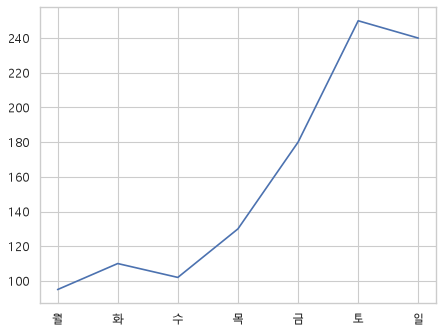

Figure Axes [7.0, 4.0]


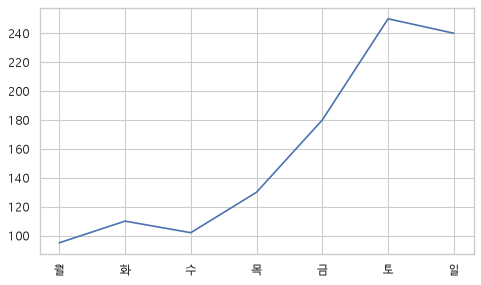

In [2]:
# 문제 1: 리스트 → 꺾은선 (plt 방식)
# 왜 · 가장 짧은 plt 방식으로 그래프의 기본 흐름을 먼저 익히기 위해
요일7 = ["월", "화", "수", "목", "금", "토", "일"]  # 가로축 이름
매출2 = [95, 110, 102, 130, 180, 250, 240]          # 홍대점 매출
plt.plot(요일7, 매출2)                              # 현재 그림판에 선 1개
plt.show()                                          # 화면에 띄움


# 문제 2: 같은 그림을 ax 방식으로 · figsize 7 × 4
# 왜 · 칸이 여러 개일 때 필요한 ax 방식을 같은 그림으로 비교하기 위해
fig, ax = plt.subplots(figsize=(7, 4))  # 그림판 fig · 그릴 칸 ax
ax.plot(요일7, 매출2)                   # ax에 직접 그림
print(type(fig).__name__, type(ax).__name__, fig.get_size_inches().tolist())  # 무엇인지 · 크기
plt.show()                              # 화면에 띄움

**결과** · 예측 정답은 `Figure` · `Axes`

- `Figure Axes [7.0, 4.0]` — fig는 Figure(그림판), ax는 Axes(칸) · 크기 가로 7 × 세로 4인치
- 그림 · 두 그림 모두 토요일이 가장 높은 선 1개

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>plt.plot()</code></td><td>현재 그림판에 자동으로</td><td>빠르게 한 장 확인할 때</td></tr>
<tr><td><code>fig, ax = plt.subplots()</code></td><td>그림판 · 칸을 변수로 받음</td><td>꾸미기 · 여러 칸 · 저장 (기본)</td></tr>
<tr><td><code>figsize=(가로, 세로)</code></td><td>인치 단위 크기</td><td>발표용 · 가로로 긴 시간 그래프</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 두 방식을 한 칸에 섞어 쓰면 어디에 그려지는지 헷갈림 (문제 4)
> - `plt.show()`를 빼면 노트북에서는 보이지만 스크립트에서는 안 보임

> ✅ **한 줄 정리** · plt 방식은 현재 그림판에 바로 그리고, ax 방식은 그림판과 칸을 변수로 받아 원하는 칸에 그리므로 꾸미기 · 여러 칸에는 ax 방식을 쓴다.

**딥러닝 코드에서는**

- 학습 곡선 코드의 기본 틀 `fig, ax = plt.subplots(figsize=(8, 4))`
- `ax.plot(train_loss, label="train")` · `ax.plot(val_loss, label="val")`

### 1-2. `A` 제목 · 축 이름 · 범례 · 고장 난 코드 · `ax.set_title` · `ax.set_xlabel` · `ax.legend` <sub>원본 문제 3 · 4</sub>

> 🎯 **`ax.title("...")`은 왜 에러가 나고, 어떻게 고치는가?**

💡 **쉽게 말하면**

- ax 방식에서 꾸미는 함수는 이름이 **`set_`으로 시작**.
- `ax.title`은 함수가 아니라 이미 있는 제목 글자 객체라 괄호로 부르면 에러.

**실행 흐름**

1. 제목 · 축 이름 · label → legend
2. 원본 고장 코드를 try로 실행
3. set_ 로 세 곳 고치기

**먼저 예측** · `ax.title("요일별 매출")`의 에러 메시지는? — 답은 코드 실행 결과 아래에

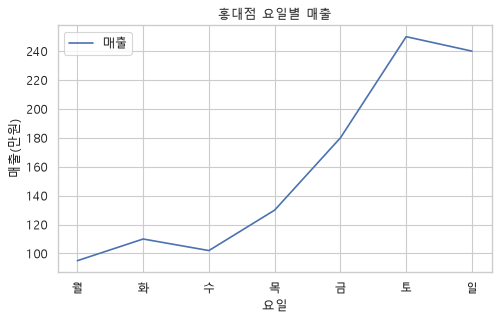

에러: 'Text' object is not callable
고친 뒤 제목: 요일별 매출


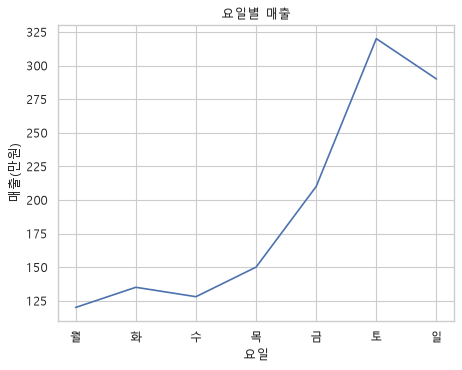

In [3]:
# 문제 3: 제목 · 축 이름 · 범례 (ax 방식은 set_ 으로 시작)
# 왜 · ax 방식에서는 set_ 으로 시작하는 메서드를 쓴다는 것을 확인하기 위해
fig, ax = plt.subplots(figsize=(7, 4))  # 그림판 + 칸
ax.plot(요일7, 매출2, label="매출")     # 범례에 쓸 이름
ax.set_title("홍대점 요일별 매출")      # 제목
ax.set_xlabel("요일")                   # 가로축 이름
ax.set_ylabel("매출(만원)")             # 세로축 이름 · 단위
ax.legend()                             # 범례 띄우기
plt.show()                              # 화면에 띄움


# 문제 4: 고장 난 코드 — ax.title(...)은 함수가 아니라 글자 객체
# 왜 · plt 방식 이름을 ax에 그대로 쓸 때 나는 에러를 미리 보기 위해
fig, ax = plt.subplots()                # 새 칸
try:                                    # 원본 그대로 실행해 보기
    ax.title("요일별 매출")             # plt.title 습관
except TypeError as e:                  # 에러 메시지 읽기
    print("에러:", e)                   # 'Text' object is not callable
ax.plot(week["요일"], week["매출"])     # 그래프 그리기
ax.set_title("요일별 매출")             # 고침 1: title → set_title
ax.set_xlabel("요일")                   # 고침 2: xlabel → set_xlabel
ax.set_ylabel("매출(만원)")             # 고침 3: ylabel → set_ylabel
print("고친 뒤 제목:", ax.get_title())  # 제목이 붙었는지
plt.show()                              # 화면에 띄움

**결과** · 예측 정답은 `'Text' object is not callable` — 글자 객체를 함수처럼 부름

- `에러: 'Text' object is not callable` — `ax.title`은 Text 객체 · 호출 불가
- `고친 뒤 제목: 요일별 매출` — `set_title` · `set_xlabel` · `set_ylabel`로 세 곳 고침
- 그림 · 첫 그림에 제목 '홍대점 요일별 매출' · 축 이름 · 왼쪽 위 범례 '매출'

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>plt.title()</code></td><td>plt 방식 · 현재 칸</td><td>칸이 하나일 때</td></tr>
<tr><td><code>ax.set_title()</code></td><td>ax 방식 · 그 칸</td><td>칸을 골라 꾸밀 때</td></tr>
<tr><td><code>ax.set(title=, ylabel=)</code></td><td>여러 개를 한 줄로</td><td>칸마다 같은 꾸미기를 할 때 (3-1)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 범례는 선에 `label=`을 준 뒤 `ax.legend()`를 불러야 나타남
> - 한 번에 한 곳만 고치고 다시 실행 (원본 규칙 2)

> ✅ **한 줄 정리** · ax 방식에서는 set_으로 시작하는 메서드로 꾸미며, ax.title을 함수처럼 부르면 에러가 난다.

**딥러닝 코드에서는**

- `ax.set(xlabel="epoch", ylabel="loss")` · `ax.legend()`로 train · val 구분
- 에러 메시지의 객체 이름(Text · ndarray)을 읽으면 원인이 바로 보임

### 1-3. `B` fig와 ax의 차이 · 한글 글꼴 · `fig.suptitle` · `plt.rcParams` · `fm.fontManager` <sub>원본 문제 5 · 6</sub>

> 🎯 **전체 제목은 왜 `fig.suptitle()`이고, 한글이 네모로 나오면 무엇을 고치는가?**

💡 **쉽게 말하면**

- fig는 **액자 전체**, ax는 액자 안의 **사진 한 장** · 전체 제목은 액자에 붙임.
- 한글이 네모 = 지금 글꼴에 한글 글자가 없음 → 한글 글꼴로 바꾸면 됨 (코드 잘못이 아님).

**실행 흐름**

1. 칸 2개 + 칸 제목 + 전체 제목
2. fig 안의 칸 수 확인
3. 글꼴 지정 3줄 · 설치 확인

**먼저 예측** · 칸 2개짜리 fig의 `fig.axes` 길이는? — 답은 코드 실행 결과 아래에

fig 안의 칸 수: 2 | 전체 제목: 강남점 일주일


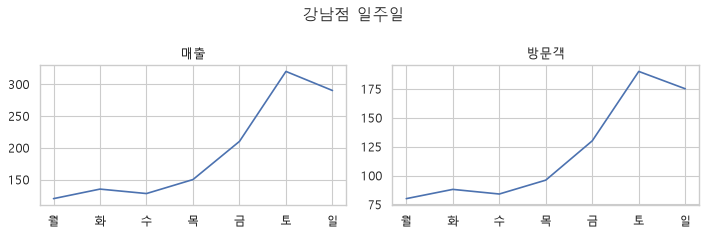

맑은 고딕 설치: True


In [4]:
# 문제 5: fig = 그림판 전체 · ax = 그 안의 칸 하나 → 전체 제목은 fig에
# 왜 · 전체 제목과 칸 제목을 넣는 위치가 다르다는 것을 구분하기 위해
fig, axes = plt.subplots(1, 2, figsize=(9, 3))  # 칸 2개
axes[0].plot(week["요일"], week["매출"])        # 왼쪽 칸
axes[0].set_title("매출")                       # 칸 제목 = ax.set_title
axes[1].plot(week["요일"], week["방문객"])      # 오른쪽 칸
axes[1].set_title("방문객")                     # 칸 제목
fig.suptitle("강남점 일주일")                   # 전체 제목 = fig.suptitle
plt.tight_layout()                              # 간격 정리
print("fig 안의 칸 수:", len(fig.axes), "| 전체 제목:", fig.get_suptitle())  # fig가 칸들을 가짐
plt.show()                                      # 화면에 띄움


# 문제 6: 한글이 네모로 나오는 원인 = 지금 글꼴에 한글 글자가 없음 → 한글 글꼴 지정 3줄
# 왜 · 한글 깨짐의 원인과 해결 3줄을 기억하기 위해
plt.rcParams["font.family"] = "Malgun Gothic"  # 1. 한글이 있는 글꼴로
plt.rcParams["axes.unicode_minus"] = False     # 2. 음수 기호가 네모가 되는 것 방지
# 3. 글꼴 확인
print("맑은 고딕 설치:", "Malgun Gothic" in {f.name for f in fm.fontManager.ttflist})

**결과** · 예측 정답은 2 — fig가 칸 두 개를 가지고 있음

- `fig 안의 칸 수: 2 | 전체 제목: 강남점 일주일` — 칸 제목은 ax · 전체 제목은 fig
- `맑은 고딕 설치: True` — 이 PC에 한글 글꼴이 있음 → `font.family`만 바꾸면 됨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>ax.set_title()</code></td><td>칸 하나의 제목</td><td>칸마다 다른 제목</td></tr>
<tr><td><code>fig.suptitle()</code></td><td>그림판 전체 제목</td><td>대시보드 이름</td></tr>
<tr><td><code>plt.rcParams["font.family"]</code></td><td>이후 모든 그림의 글꼴</td><td>노트북 맨 위에서 한 번</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `axes.unicode_minus = False`를 빼면 음수 기호가 네모로 나옴
> - Colab은 글꼴을 설치한 뒤 경로를 등록해야 함 · Windows는 맑은 고딕이 이미 있음

> ✅ **한 줄 정리** · fig는 그림판 전체, ax는 그 안의 칸이라 전체 제목은 fig.suptitle로 붙이고, 한글 네모는 한글 글꼴을 지정해 고친다.

**딥러닝 코드에서는**

- `fig.suptitle(f"epoch {e}")` · 칸마다 `ax.set_title("loss")` · `ax.set_title("acc")`
- 새 환경(Colab · 서버)에서는 글꼴부터 지정하는 셀을 맨 위에

---
## 2. 질문 4종 · 그림 4종

> **이 장의 흐름**
>
> - 질문 4개를 그래프 4종에 짝짓고 꺾은선부터 그림
> - 그다음 막대 정렬 · 가로 막대 · 산점도 · 히스토그램 bins를 차례로 다룸

<img src="images/st2_four.png" alt="변화 · 비교 · 관계 · 분포 → 그림 4종" width="988">

**파이프라인 위치** · ③ 해석 → ④ 전달

### 2-1. `A` 질문 ↔ 그림 짝 · 꺾은선 · `ax.plot(marker="o")` <sub>원본 문제 7 · 8</sub>

> 🎯 **'12개월 회원 수 변화' · '지점 비교' · '광고비와 매출' · '나이 분포'는 각각 어떤 그림인가?**

💡 **쉽게 말하면**

- **변화** → 꺾은선 · **비교** → 막대 · **관계** → 산점도 · **분포** → 히스토그램.
- 꺾은선에는 점(마커)을 찍어 실제 값이 있는 자리를 보여 줌.

**실행 흐름**

1. 질문 4개 → 그림 이름 출력
2. 요일별 방문객 꺾은선 · 동그라미 마커
3. 제목 · 단위 넣은 세로축 이름

**먼저 예측** · '우리 손님 나이는 몇 살대에 몰려 있나'는? — 답은 코드 실행 결과 아래에

(1) 12개월 회원 수 변화 → 꺾은선 (시간 + 수치)
(2) 지점 5곳 매출 비교 → 막대 (범주 + 값)
(3) 광고비와 매출의 관계 → 산점도 (수치 + 수치)
(4) 손님 나이 분포 → 히스토그램 (수치 1개)


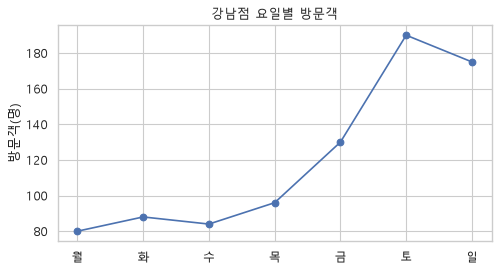

In [5]:
# 문제 7: 질문 → 그래프 (변수 개수 · 유형)
# 왜 · 질문을 변수 개수 · 유형으로 바꿔 그래프를 고르는 규칙을 익히기 위해
pairs = {"(1) 12개월 회원 수 변화": "꺾은선 (시간 + 수치)",   # 시간 흐름
         "(2) 지점 5곳 매출 비교": "막대 (범주 + 값)",        # 항목 비교
         "(3) 광고비와 매출의 관계": "산점도 (수치 + 수치)",  # 관계
         "(4) 손님 나이 분포": "히스토그램 (수치 1개)"}       # 분포
for q, a in pairs.items():                                    # 질문마다
    print(q, "→", a)                                          # 답


# 문제 8: 요일별 방문객 꺾은선 · 동그라미 마커 · 단위가 든 세로축 이름
# 왜 · 마커와 단위가 든 축 이름으로 읽기 쉬운 꺾은선을 만들기 위해
fig, ax = plt.subplots(figsize=(7, 3.5))           # 칸 1개
ax.plot(week["요일"], week["방문객"], marker="o")  # 점마다 동그라미
ax.set_title("강남점 요일별 방문객")               # 제목
ax.set_ylabel("방문객(명)")                        # 단위 포함
plt.show()                                         # 화면에 띄움

**결과** · 예측 정답은 히스토그램 (수치 1개의 분포)

- `(1) 12개월 회원 수 변화 → 꺾은선 (시간 + 수치)` — 시간 흐름
- `(2) 지점 5곳 매출 비교 → 막대 (범주 + 값)` — 항목 비교
- `(3) 광고비와 매출의 관계 → 산점도 (수치 + 수치)` — 두 수치의 관계
- `(4) 손님 나이 분포 → 히스토그램 (수치 1개)` — 분포
- 그림 · 요일별 방문객이 금요일부터 뛰어 토요일에 가장 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>꺾은선 <code>plot</code></td><td>순서가 있는 가로축 · 흐름</td><td>시간 · 요일 · epoch</td></tr>
<tr><td>막대 <code>bar</code></td><td>항목끼리 크기</td><td>지점 · 메뉴</td></tr>
<tr><td>산점도 <code>scatter</code></td><td>점마다 두 수치</td><td>광고비 vs 매출</td></tr>
<tr><td>히스토그램 <code>hist</code></td><td>구간별 개수</td><td>나이 · 일매출 분포</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 세로축 이름에는 단위를 · '방문객(명)' · '매출(만원)'
> - 순서 없는 범주를 꺾은선으로 이으면 흐름이 있는 것처럼 보임 (문제 15)

> ✅ **한 줄 정리** · 질문이 변화면 꺾은선, 비교면 막대, 관계면 산점도, 분포면 히스토그램이고, 꺾은선에는 마커와 단위를 넣는다.

**딥러닝 코드에서는**

- epoch별 loss = 꺾은선 · 클래스 개수 = 막대 · 예측 vs 실제 = 산점도 · 가중치 = 히스토그램
- 통계 파일별 1의 5장 '차트 고르기'와 같은 기준

### 2-2. `A` 막대 정렬 · 가로 막대 · 잘못 고른 그래프 · `sort_values` · `ax.barh` · `invert_yaxis` <sub>원본 문제 9 · 10 · 15</sub>

> 🎯 **판매량 1등이 가로 막대의 맨 위에 오게 하려면?**

💡 **쉽게 말하면**

- 막대는 **큰 순서로 정렬**하면 순위가 바로 읽힘.
- `barh`는 첫 행을 **맨 아래**에 그림 → 축을 뒤집거나 오름차순으로 넣음.

**실행 흐름**

1. 판매량 내림차순 정렬
2. 세로 막대 · 세로축 0부터
3. 가로 막대 · `invert_yaxis` · 범주 꺾은선을 막대로

**먼저 예측** · 내림차순으로 정렬한 표를 `barh`에 그대로 넣으면 1등은 위 · 아래 중 어디에? — 답은 코드 실행 결과 아래에

정렬: ['아메리카노', '라떼', '콜드브루', '샌드위치', '마카롱']


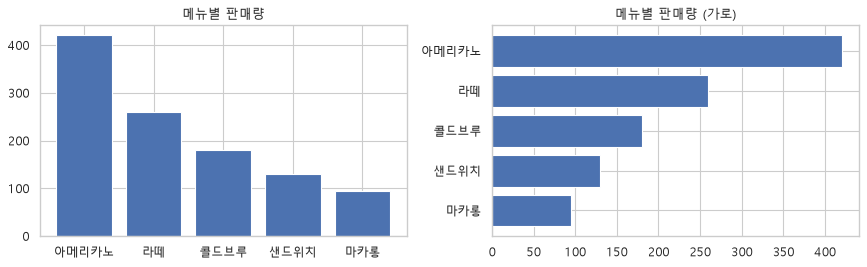

맨 위 막대: 아메리카노


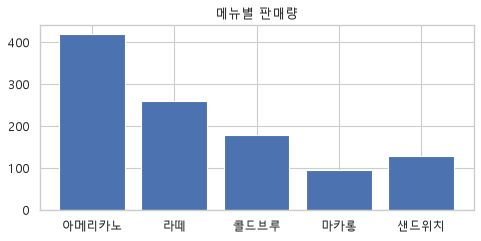

In [6]:
# 문제 9: 판매량이 큰 순서로 세로 막대 · 세로축 0부터
# 왜 · 정렬하고 0부터 시작해야 막대 길이 비교가 정확해지기 때문에
m_sorted = menu.sort_values("판매량", ascending=False)  # 큰 순서
print("정렬:", m_sorted["메뉴"].tolist())               # 막대 순서
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))       # 문제 9 · 10을 나란히
axes[0].bar(m_sorted["메뉴"], m_sorted["판매량"])       # 세로 막대
axes[0].set_ylim(bottom=0)                              # 세로축 0에서 시작
axes[0].set_title("메뉴별 판매량")                      # 제목


# 문제 10: 가로 막대 · 1등이 맨 위 (barh는 첫 행을 아래에 그림 → 축 뒤집기)
# 왜 · 항목 이름이 길 때 가로 막대로 읽기 쉽게, 1등이 위에 오게 하기 위해
axes[1].barh(m_sorted["메뉴"], m_sorted["판매량"])             # 가로 막대
axes[1].invert_yaxis()                                         # 첫 행(1등)을 맨 위로
axes[1].set_title("메뉴별 판매량 (가로)")                      # 제목
plt.tight_layout()                                             # 간격 정리
plt.show()                                                     # 화면에 띄움
print("맨 위 막대:", axes[1].get_yticklabels()[0].get_text())  # 1등 확인


# 문제 15: 메뉴(범주)를 꺾은선으로 이으면 '메뉴 사이에 흐름'이 있는 것처럼 보임 → 막대로
# 왜 · 순서 없는 범주를 선으로 이으면 생기는 오해를 보이기 위해
fig, ax = plt.subplots(figsize=(7, 3))  # 칸 1개
ax.bar(menu["메뉴"], menu["판매량"])    # 고침: 범주 비교는 막대
ax.set_title("메뉴별 판매량")           # 제목
plt.show()                              # 화면에 띄움

**결과** · 예측 정답은 맨 아래 — 그래서 `invert_yaxis()`로 뒤집음

- `정렬: ['아메리카노', '라떼', '콜드브루', '샌드위치', '마카롱']` — 큰 순서
- `맨 위 막대: 아메리카노` — 축을 뒤집은 뒤 1등이 맨 위
- 그림 · 문제 15의 꺾은선은 메뉴 사이에 '흐름'이 생겨 틀림 → 막대로 고침

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정렬 안 한 막대</td><td>원본 순서</td><td>순서 자체에 뜻이 있을 때 (요일)</td></tr>
<tr><td>내림차순 세로 막대</td><td>순위가 왼쪽부터</td><td>항목 5 ~ 7개</td></tr>
<tr><td>가로 막대 + 1등 위</td><td>긴 이름 · 많은 항목</td><td>메뉴 · 지역 순위</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 세로축이 0에서 시작하지 않으면 차이가 부풀려짐 (6-1)
> - 범주를 꺾은선으로 그리면 에러 없이 잘못된 그림이 나옴 → 눈으로 확인

> ✅ **한 줄 정리** · 비교용 막대는 큰 순서로 정렬하고 세로축을 0부터 시작하며, 가로 막대는 invert_yaxis로 1등을 맨 위에 둔다.

**딥러닝 코드에서는**

- 특성 중요도 · 클래스별 정확도를 정렬한 가로 막대로
- `df.sort_values(...)` 뒤에 그리는 습관

### 2-3. `A` 산점도 · 경향과 원인 · `ax.scatter(alpha=, s=)` · `Series.corr` <sub>원본 문제 11 · 12</sub>

> 🎯 **산점도를 보고 '방문객이 늘어서 매출이 늘었다'고 말해도 되는가?**

💡 **쉽게 말하면**

- 점 84개가 겹치므로 **반투명 · 작은 점**으로 그림.
- 산점도가 보여 주는 것은 **함께 움직이는 경향**까지 · 원인은 따로 확인.

**실행 흐름**

1. `alpha=0.4` · `s=20` 산점도
2. 상관계수
3. (가) · (나) 중 고르기

**먼저 예측** · 방문객과 일매출의 상관계수는 0.5보다 클까? — 답은 코드 실행 결과 아래에

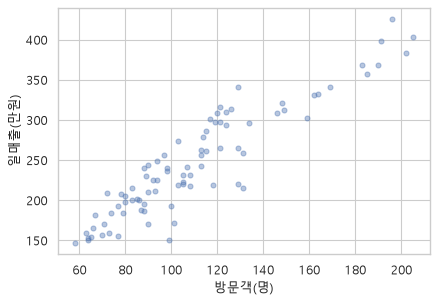

상관계수 0.920 → (나) 방문객이 많은 날은 매출도 높은 경향


In [7]:
# 문제 11: 방문객 vs 일매출 산점도 · 84개 점이 겹치므로 투명도 · 크기 조정
# 왜 · 점이 겹쳐 밀도가 안 보이는 문제를 투명도 · 크기로 해결하기 위해
fig, ax = plt.subplots(figsize=(6, 4))                         # 칸 1개
ax.scatter(sales["방문객"], sales["일매출"], alpha=0.4, s=20)  # 반투명 · 작은 점
ax.set_xlabel("방문객(명)")                                    # 가로 = 방문객
ax.set_ylabel("일매출(만원)")                                  # 세로 = 일매출
plt.show()                                                     # 화면에 띄움


# 문제 12: 산점도가 말해 주는 것 = 경향(상관) · 원인은 아님
# 왜 · 상관계수는 경향을 말할 뿐 원인은 아니라는 것을 확인하기 위해
r = sales["방문객"].corr(sales["일매출"])                              # 상관계수
print(f"상관계수 {r:.3f} → (나) 방문객이 많은 날은 매출도 높은 경향")  # 정답 (나)

**결과** · 예측 정답은 큼 — 0.920 · 답은 (나)

- `상관계수 0.920 → (나) 방문객이 많은 날은 매출도 높은 경향` — 강한 양의 상관 · 인과는 아님
- 그림 · 오른쪽 위로 올라가는 띠 · 지점별로 무리가 나뉘어 보임 (5-2에서 색으로 구분)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>(가) 늘어서 늘었다</td><td>원인을 단정</td><td>실험 · 추가 분석 뒤에만</td></tr>
<tr><td>(나) 높은 경향이 있다</td><td>함께 움직임만 말함</td><td>산점도 해석의 기본</td></tr>
<tr><td><code>alpha</code> · <code>s</code></td><td>투명도 · 점 크기</td><td>점이 많아 겹칠 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 주말 · 지점 같은 다른 변수가 둘 다를 움직일 수 있음
> - 점이 겹치면 실제보다 적어 보임 → 투명도

> ✅ **한 줄 정리** · 산점도는 두 수치가 함께 움직이는 경향을 보여 줄 뿐 원인을 증명하지 않으며, 점이 많으면 투명도와 크기를 줄인다.

**딥러닝 코드에서는**

- 예측값 vs 실제값 산점도 · 점이 대각선에 붙을수록 좋은 모델
- 임베딩 2차원 산점도에 `alpha=0.3`

### 2-4. `A` 히스토그램 bins · 막대와의 차이 · `ax.hist(bins=)` <sub>원본 문제 13 · 14</sub>

> 🎯 **bins 5 · 20 · 60의 히스토그램은 어떻게 다르고, 막대그래프와는 무엇이 다른가?**

💡 **쉽게 말하면**

- bins가 적으면 뭉뚱그려지고, 많으면 빈 구간과 잡음이 생김.
- 막대는 가로가 **범주**, 히스토그램은 가로가 **수치 구간**.

**실행 흐름**

1. 가로 3칸에 bins만 바꿔 그림
2. 가장 큰 막대 · 빈 구간 세기
3. 가로축 · 세로축 비교

**먼저 예측** · bins=60이면 84일 중 빈 구간은 몇 개쯤? — 답은 코드 실행 결과 아래에

bins= 5 | 가장 큰 막대 27일 | 빈 구간 0개
bins=20 | 가장 큰 막대 9일 | 빈 구간 2개
bins=60 | 가장 큰 막대 5일 | 빈 구간 17개


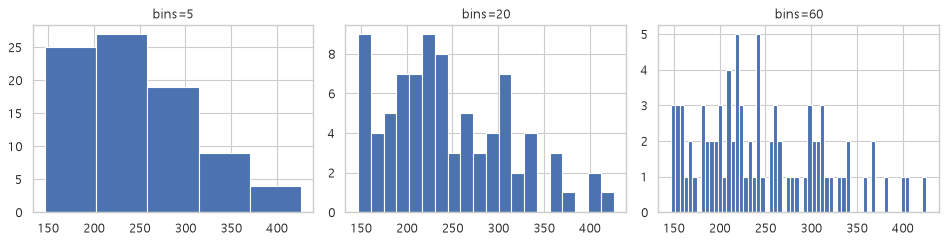

막대 | 가로: 범주(메뉴) | 세로: 값(판매량)
히스토그램 | 가로: 수치 구간(일매출) | 세로: 그 구간의 개수(일수)


In [8]:
# 문제 13: 일매출 히스토그램을 가로 3칸에 · bins 5 · 20 · 60
# 왜 · bins에 따라 같은 분포가 다르게 보인다는 것을 나란히 비교하기 위해
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))  # 가로 3칸
for ax, b in zip(axes, [5, 20, 60]):               # bins만 바꿈
    n, _, _ = ax.hist(sales["일매출"], bins=b)     # n = 구간별 개수
    ax.set_title(f"bins={b}")                      # 칸 제목에 bins
    print(f"bins={b:>2} | 가장 큰 막대 {int(n.max())}일 | 빈 구간 {(n == 0).sum()}개")  # 줌 비교
plt.tight_layout()                                 # 간격 정리
plt.show()                                         # 화면에 띄움


# 문제 14: 막대그래프 vs 히스토그램 (가로축 · 세로축 기준)
# 왜 · 가로축이 범주인지 구간인지로 두 그래프를 구분하기 위해
print("막대 | 가로: 범주(메뉴) | 세로: 값(판매량)")                         # 항목마다 막대
print("히스토그램 | 가로: 수치 구간(일매출) | 세로: 그 구간의 개수(일수)")  # 구간마다 막대

**결과** · 예측 정답은 17개 — 구간이 너무 잘게 나뉨

- `bins= 5 | 가장 큰 막대 27일 | 빈 구간 0개` — 큰 흐름만
- `bins=20 | 가장 큰 막대 9일 | 빈 구간 2개` — 모양과 디테일이 함께
- `bins=60 | 가장 큰 막대 5일 | 빈 구간 17개` — 잡음 · 빈칸
- `막대 | 가로: 범주(메뉴) | 세로: 값(판매량)` — 문제 14 답 · 막대
- `히스토그램 | 가로: 수치 구간(일매출) | 세로: 그 구간의 개수(일수)` — 문제 14 답 · 히스토그램

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>막대그래프</td><td>가로 = 범주 · 막대 사이 간격</td><td>메뉴별 판매량</td></tr>
<tr><td>히스토그램</td><td>가로 = 수치 구간 · 막대가 붙음</td><td>일매출 분포</td></tr>
<tr><td>bins</td><td>구간 개수 (카메라 줌)</td><td>데이터 양 · 구간 폭의 뜻을 보고</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - bins를 바꿔 원하는 모양을 만드는 것은 속이기
> - 칸마다 bins가 다르면 막대 높이를 서로 비교하지 않기

> ✅ **한 줄 정리** · 히스토그램은 수치 구간별 개수를 보여 주며 bins에 따라 모양이 달라지고, 막대그래프는 범주별 값을 보여 준다.

**딥러닝 코드에서는**

- `plt.hist(model.fc.weight.flatten(), bins=50)`로 가중치 분포 확인
- 통계 파일별 1의 3-2와 같은 '카메라 줌'

---
## 3. 여러 그림을 한 판에

> **이 장의 흐름**
>
> - 가로 2칸 · 2행 2열로 칸을 나눠 각각 그림
> - 그다음 세로축을 맞추고, axes 배열에서 나는 에러를 고침

<img src="images/st2_grid.png" alt="subplots로 칸을 나누고 axes 번호로 칸을 고름" width="793">

**파이프라인 위치** · ④ 전달 (비교)

### 3-1. `A` 가로 2칸 · 2행 2열 대시보드 · `plt.subplots(2, 2)` · `ax.set(...)` · `fig.suptitle` <sub>원본 문제 16 · 17</sub>

> 🎯 **2행 2열 대시보드에서 오른쪽 아래 칸은 어떻게 고르는가?**

💡 **쉽게 말하면**

- `plt.subplots(2, 2)`의 axes는 **2 × 2 표** · `axes[행, 열]`로 칸을 고름.
- 칸마다 제목 · 단위, 그림판에는 전체 제목.

**실행 흐름**

1. 1행 2열 · 칸마다 제목 · 단위
2. 2행 2열 · 칸 4개에 그림 4종
3. 전체 제목 · `tight_layout`

**먼저 예측** · `plt.subplots(2, 2)`의 axes 모양은? — 답은 코드 실행 결과 아래에

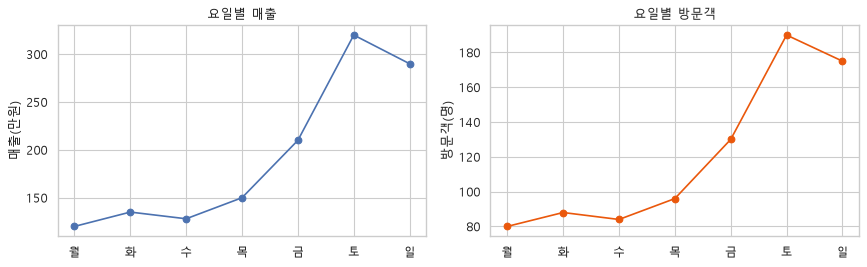

axes 모양: (2, 2)


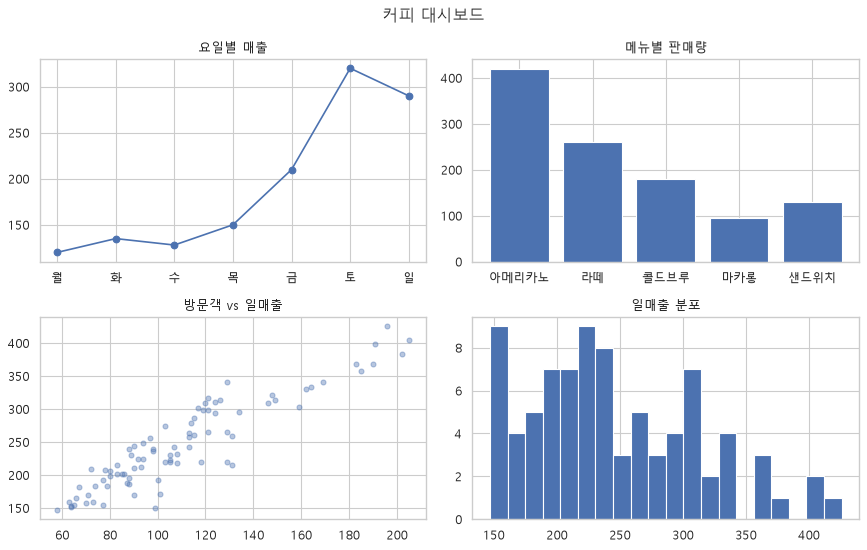

In [9]:
# 문제 16: 가로 2칸 · 칸마다 제목과 단위 · 겹치지 않게
# 왜 · 칸마다 제목 · 단위를 달고 겹치지 않게 배치하는 법을 익히기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                        # 1행 2열
axes[0].plot(week["요일"], week["매출"], marker="o")                     # 왼쪽 = 매출
axes[0].set(title="요일별 매출", ylabel="매출(만원)")                    # 제목 · 단위
axes[1].plot(week["요일"], week["방문객"], marker="o", color="#ea580c")  # 오른쪽 = 방문객
axes[1].set(title="요일별 방문객", ylabel="방문객(명)")                  # 제목 · 단위
plt.tight_layout()                                                       # 겹침 정리
plt.show()                                                               # 화면에 띄움


# 문제 17: 2행 2열 대시보드 · 전체 제목
# 왜 · 2차원 axes 배열에서 칸을 골라 그리는 법을 익히기 위해
fig, axes = plt.subplots(2, 2, figsize=(11, 7))                        # axes는 2 × 2 배열
axes[0, 0].plot(week["요일"], week["매출"], marker="o")                # 왼쪽 위 · 꺾은선
axes[0, 0].set_title("요일별 매출")                                    # 제목
axes[0, 1].bar(menu["메뉴"], menu["판매량"])                           # 오른쪽 위 · 막대
axes[0, 1].set_title("메뉴별 판매량")                                  # 제목
axes[1, 0].scatter(sales["방문객"], sales["일매출"], alpha=0.4, s=20)  # 왼쪽 아래 · 산점도
axes[1, 0].set_title("방문객 vs 일매출")                               # 제목
axes[1, 1].hist(sales["일매출"], bins=20)                              # 오른쪽 아래 · 히스토그램
axes[1, 1].set_title("일매출 분포")                                    # 제목
fig.suptitle("커피 대시보드")                                          # 전체 제목
plt.tight_layout()                                                     # 간격 정리
print("axes 모양:", axes.shape)                                        # [행, 열]로 칸 고르기
plt.show()                                                             # 화면에 띄움

**결과** · 예측 정답은 `(2, 2)` — 오른쪽 아래는 `axes[1, 1]`

- `axes 모양: (2, 2)` — 행 2 · 열 2
- 그림 · 첫 그림은 매출 · 방문객 두 칸, 둘째 그림은 꺾은선 · 막대 · 산점도 · 히스토그램 4칸 대시보드

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>plt.subplots(1, 2)</code></td><td>axes 모양 (2,) · <code>axes[0]</code></td><td>두 그래프를 나란히</td></tr>
<tr><td><code>plt.subplots(2, 2)</code></td><td>axes 모양 (2, 2) · <code>axes[1, 1]</code></td><td>대시보드</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>제목 · 눈금 겹침 정리</td><td>칸이 2개 이상일 때 항상</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `tight_layout`을 빼면 칸 제목과 눈금 글자가 겹침
> - 칸이 많을수록 그림판 크기(figsize)도 키우기

> ✅ **한 줄 정리** · plt.subplots(행, 열)의 axes는 배열이라 axes[행, 열]로 칸을 골라 그리고, 겹침은 tight_layout으로 정리한다.

**딥러닝 코드에서는**

- `fig, axes = plt.subplots(1, 2)` → `axes[0]`에 loss · `axes[1]`에 accuracy
- 이미지 여러 장은 `for ax, img in zip(axes.flat, images)`

### 3-2. `A` 세로축 맞추기 · sharey · `plt.subplots(sharey=True)` · `ax.get_ylim` <sub>원본 문제 18</sub>

> 🎯 **지점 3곳의 히스토그램을 나란히 놓을 때 세로축이 다르면 무엇이 문제인가?**

💡 **쉽게 말하면**

- 칸마다 세로축 눈금이 다르면 **같은 높이가 다른 숫자**라 비교가 틀어짐.
- `sharey=True`면 세 칸이 같은 눈금을 씀.

**실행 흐름**

1. `sharey=True`로 1행 3열
2. 지점마다 히스토그램
3. 세 칸의 세로축 범위 확인

**먼저 예측** · 세 칸의 세로축 범위는 같을까? — 답은 코드 실행 결과 아래에

세 칸의 세로축 범위: [(0.0, 7.3), (0.0, 7.3), (0.0, 7.3)]


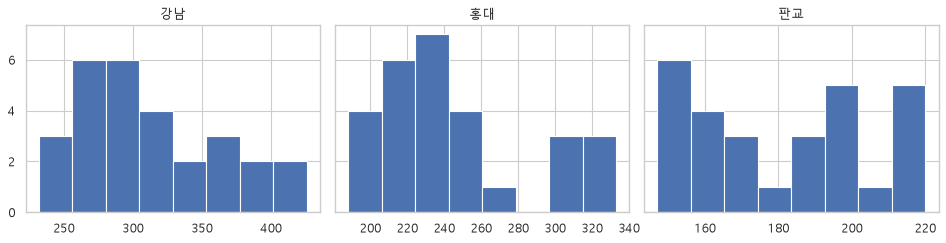

In [10]:
# 문제 18: 지점 3곳 일매출 히스토그램 · 세로축 눈금을 같게 (sharey)
# 왜 · sharey로 눈금을 같게 해야 지점끼리 공정하게 비교되기 때문에
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)   # 세 칸이 세로축 공유
for ax, name in zip(axes, ["강남", "홍대", "판교"]):             # 지점마다
    ax.hist(sales.loc[sales["지점"] == name, "일매출"], bins=8)  # 그 지점의 28일
    ax.set_title(name)                                           # 칸 제목
plt.tight_layout()                                               # 간격 정리
# 같음
print("세 칸의 세로축 범위:", [tuple(round(float(v), 1) for v in ax.get_ylim()) for ax in axes])
plt.show()                                                       # 화면에 띄움

**결과** · 예측 정답은 같음 — 모두 `(0.0, 7.3)`

- `세 칸의 세로축 범위: [(0.0, 7.3), (0.0, 7.3), (0.0, 7.3)]` — 공유된 세로축
- 그림 · 강남은 오른쪽(높은 매출)에, 판교는 왼쪽에 몰림 · 가로축은 칸마다 다름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>sharey=True</code></td><td>세로 눈금 공유</td><td>개수 · 값의 높이를 비교할 때</td></tr>
<tr><td><code>sharex=True</code></td><td>가로 눈금 공유</td><td>같은 구간에서 위치를 비교할 때</td></tr>
<tr><td>공유 없음</td><td>칸마다 자동 범위</td><td>단위가 다른 그래프</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 가로축은 여전히 다름 · 위치까지 비교하려면 `sharex=True`도
> - 공유하면 작은 값의 칸은 납작하게 보일 수 있음 (정상)

> ✅ **한 줄 정리** · 칸끼리 높이를 비교하려면 sharey=True로 세로축을 맞춰야 하며, 가로 위치까지 비교하려면 sharex도 맞춘다.

**딥러닝 코드에서는**

- 모델 3개의 loss 곡선을 칸으로 나눌 때 `sharey=True`
- 같은 축이 아니면 '어느 모델이 더 낮다'는 판단이 틀림

### 3-3. `A` axes 배열 에러 · 겹칠까 나눌까 · `axes[0]` · `AttributeError` <sub>원본 문제 19 · 20</sub>

> 🎯 **`'numpy.ndarray' object has no attribute 'set_title'`은 무슨 뜻인가?**

💡 **쉽게 말하면**

- 칸이 2개 이상이면 axes는 **칸들을 담은 배열** · 배열에는 set_title이 없음.
- 단위가 같으면 한 칸에 겹치고, 다르면 칸을 나눔.

**실행 흐름**

1. axes의 자료형 · 모양 확인
2. 원본 고장 코드를 try로
3. `axes[0]` · `axes[1]`로 고침 · 단위로 판단

**먼저 예측** · `plt.subplots(1, 2)`의 axes 모양은? — 답은 코드 실행 결과 아래에

axes 정체: ndarray (2,)
에러: 'numpy.ndarray' object has no attribute 'set_title'


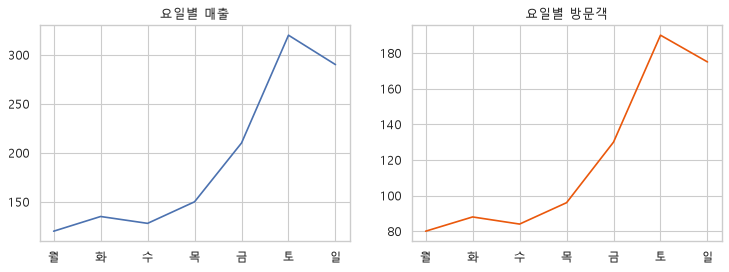

(1) 강남 vs 홍대 매출 | 단위 만원 · 만원 → 겹쳐 그리기
(2) 일매출 vs 방문객 | 단위 만원 · 명 → 칸 나누기


In [11]:
# 문제 19: plt.subplots(1, 2)의 axes는 칸 2개짜리 배열 → 칸을 골라서 그려야 함
# 왜 · axes 배열에 바로 그리려다 나는 에러를 미리 보기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))     # 칸 2개
print("axes 정체:", type(axes).__name__, axes.shape)  # ndarray (2,)
try:                                                  # 원본 그대로
    axes.set_title("요일별 매출")                     # 배열에는 set_title이 없음
except AttributeError as e:                           # 에러 메시지 읽기
    print("에러:", e)                                 # 'numpy.ndarray' object has no attribute ...
axes[0].plot(week["요일"], week["매출"])              # 고침: axes[0] = 첫 칸
axes[0].set_title("요일별 매출")                      # 칸에 제목
axes[1].plot(week["요일"], week["방문객"], color="#ea580c")  # 둘째 칸 = axes[1]
axes[1].set_title("요일별 방문객")                    # 칸에 제목
plt.show()                                            # 화면에 띄움


# 문제 20: 단위가 같으면 한 칸에 겹치고, 다르면 칸을 나눔
# 왜 · 단위에 따라 한 칸에 겹칠지 나눌지 정하는 기준을 세우기 위해
for case, unit, how in [("(1) 강남 vs 홍대 매출", "만원 · 만원", "겹쳐 그리기"),  # 같은 축 비교
                        ("(2) 일매출 vs 방문객", "만원 · 명", "칸 나누기")]:      # 단위가 다름
    print(f"{case} | 단위 {unit} → {how}")                                        # 판단

**결과** · 예측 정답은 `(2,)` — 칸 2개짜리 1차원 배열

- `axes 정체: ndarray (2,)` — 칸 2개를 담은 NumPy 배열
- `에러: 'numpy.ndarray' object has no attribute 'set_title'` — 배열에 칸 메서드를 부름
- `(1) 강남 vs 홍대 매출 | 단위 만원 · 만원 → 겹쳐 그리기` — 같은 축에서 바로 비교
- `(2) 일매출 vs 방문객 | 단위 만원 · 명 → 칸 나누기` — 축이 하나로는 안 맞음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>fig, ax = plt.subplots()</code></td><td>칸 1개 → Axes</td><td>단일 그림</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2)</code></td><td>칸 여러 개 → 배열</td><td><code>axes[0]</code>로 골라 씀</td></tr>
<tr><td>한 칸에 겹치기</td><td>같은 단위 · 같은 축</td><td>강남 vs 홍대 매출</td></tr>
<tr><td>칸 나누기</td><td>다른 단위</td><td>매출(만원) vs 방문객(명)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 변수 이름을 칸 1개면 `ax`, 여러 개면 `axes`로 구분해 실수 방지
> - 단위가 다른 두 선을 한 칸에 억지로 넣으면 이중축 문제 (6-2)

> ✅ **한 줄 정리** · 칸이 여러 개면 axes는 배열이라 axes[0]처럼 칸을 골라야 하고, 단위가 같으면 겹치고 다르면 칸을 나눈다.

**딥러닝 코드에서는**

- `plt.subplots(1, 1)`도 칸 1개 · 2개 이상일 때만 배열
- `squeeze=False`를 주면 항상 2차원 배열 → 반복문이 편함

---
## 4. 꾸미기와 저장

> **이 장의 흐름**
>
> - 선 스타일 · 축 범위 · 눈금 · 격자를 정리
> - 그다음 하나만 강조하고 화살표를 단 뒤, 파일로 저장하고 제목을 '발견한 사실'로 고침

<img src="images/st2_style.png" alt="기본 그림 → 강조 · 주석 · 사실 제목" width="988">

**파이프라인 위치** · ④ 전달 (발표 · 보고)

### 4-1. `B` 선 스타일 · 축과 눈금 · `linestyle` · `set_ylim` · `tick_params` · `set_axisbelow` <sub>원본 문제 21 · 22</sub>

> 🎯 **격자선이 막대 위로 올라오지 않고 가로 방향만 연하게 보이게 하려면?**

💡 **쉽게 말하면**

- 선은 색 · 모양 · 굵기 · 마커를 인자로 바꿈.
- 격자는 `grid(axis="y", alpha=0.3)` + `set_axisbelow(True)`로 막대 뒤에.

**실행 흐름**

1. 주황 점선 · 굵기 2 · 네모 마커 8
2. 세로축 0 ~ 500 · 글자 30도
3. 가로 격자만 · 막대 뒤로

**먼저 예측** · 점선의 linestyle 값은? — 답은 코드 실행 결과 아래에

#e8590c -- 2.0 s
세로축: (0.0, 500.0)


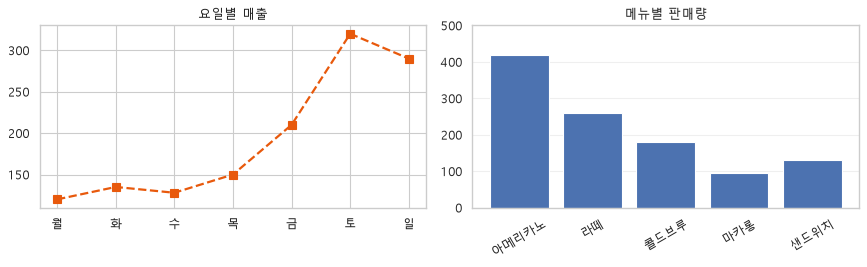

In [12]:
# 문제 21: 색 · 점선 · 굵기 2 · 네모 마커 크기 8
# 왜 · 선 모양 옵션으로 강조할 선을 구분하기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                          # 문제 21 · 22 나란히
axes[0].plot(week["요일"], week["매출"], color="#e8590c", linestyle="--",  # 색 · 점선
             linewidth=2, marker="s", markersize=8)                        # 굵기 · 네모 · 크기
axes[0].set_title("요일별 매출")                                           # 제목


# 문제 22: 세로축 0 ~ 500 · 가로 글자 30도 · 가로 격자만 연하게 · 격자는 막대 뒤
# 왜 · 축 범위 · 글자 각도 · 격자를 정리해 읽기 쉬운 그래프를 만들기 위해
axes[1].bar(menu["메뉴"], menu["판매량"])                      # 막대
axes[1].set_ylim(0, 500)                                       # 세로축 고정
axes[1].tick_params(axis="x", rotation=30)                     # 가로 글자 기울이기
axes[1].grid(False)                                            # 스타일 기본 격자 끄기
axes[1].grid(axis="y", alpha=0.3)                              # 가로 방향 격자만 연하게
axes[1].set_axisbelow(True)                                    # 격자를 막대 뒤로
axes[1].set_title("메뉴별 판매량")                             # 제목
plt.tight_layout()                                             # 간격 정리
line = axes[0].get_lines()[0]                                  # 문제 21의 선
print(line.get_color(), line.get_linestyle(), line.get_linewidth(), line.get_marker())  # 확인
print("세로축:", tuple(float(v) for v in axes[1].get_ylim()))  # (0.0, 500.0)
plt.show()                                                     # 화면에 띄움

**결과** · 예측 정답은 `--`

- `#e8590c -- 2.0 s` — 색 · 점선 · 굵기 2 · 네모(s) 마커
- `세로축: (0.0, 500.0)` — 범위 고정
- 그림 · 오른쪽 막대 그래프는 메뉴 이름이 30도 기울고 가로 격자만 막대 뒤에 연하게 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>color · linestyle · linewidth · marker</code></td><td>선 하나의 모양</td><td>강조 · 구분</td></tr>
<tr><td><code>set_ylim(0, 500)</code></td><td>축 범위 고정</td><td>여러 그림을 같은 범위로</td></tr>
<tr><td><code>tick_params(rotation=30)</code></td><td>눈금 글자 기울기</td><td>이름이 길 때</td></tr>
<tr><td><code>grid(axis="y")</code> + <code>set_axisbelow(True)</code></td><td>가로 격자 · 막대 뒤</td><td>막대 높이 읽기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - seaborn 스타일은 기본 격자가 있어 먼저 `grid(False)`로 끄고 다시 그림
> - 색은 의미 있는 곳(강조)에만 · 장식용 색은 줄이기

> ✅ **한 줄 정리** · 선 모양은 plot의 인자로, 축은 set_ylim과 tick_params로, 격자는 grid와 set_axisbelow로 정리한다.

**딥러닝 코드에서는**

- train은 실선 · val은 점선으로 구분
- `ax.set_ylim(0, 1)`로 정확도 그래프 범위를 고정해 모델끼리 비교

### 4-2. `A` 하나만 강조 · 화살표 주석 · `color=[...]` · `ax.annotate` <sub>원본 문제 23 · 24</sub>

> 🎯 **금요일 막대만 주황색으로 하려면 막대를 두 번 그려야 하는가?**

💡 **쉽게 말하면**

- 두 번 그리면 덮어씀 → **막대마다 색 목록**을 만들어 한 번에 그림.
- `annotate`는 가리킬 점(xy)과 글자 자리(xytext)를 따로 줌.

**실행 흐름**

1. 요일마다 색 목록 (금 = 주황)
2. 막대 한 번
3. 토요일 점에 화살표 · 글자는 수요일 위

**먼저 예측** · 꺾은선에서 토요일의 x 위치 숫자는? (월 = 0) — 답은 코드 실행 결과 아래에

주황 막대: ['금']


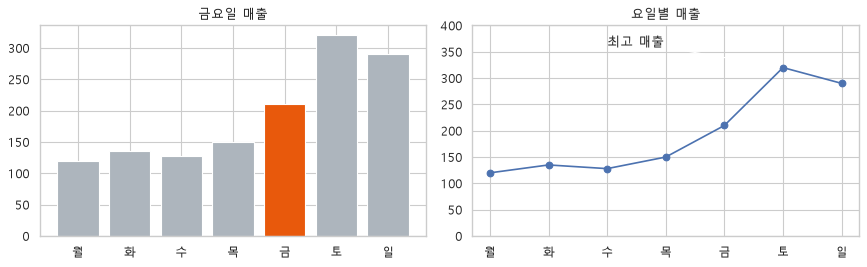

In [13]:
# 문제 23: 금요일 하나만 주황 · 나머지 회색 (색 목록을 한 번에)
# 왜 · 강조할 막대 하나만 색을 달리해 시선을 모으기 위해
colors = ["#e8590c" if d == "금" else "#adb5bd" for d in week["요일"]]  # 막대마다 색
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                       # 문제 23 · 24 나란히
axes[0].bar(week["요일"], week["매출"], color=colors)                   # 한 번만 그림
axes[0].set_title("금요일 매출")                                        # 제목
print("주황 막대:", [d for d, c in zip(week["요일"], colors) if c == "#e8590c"])  # 강조된 요일


# 문제 24: 토요일(320)을 가리키는 화살표 + '최고 매출' (글자는 수요일 위 360 근처)
# 왜 · 말로 설명할 핵심을 그래프 안에 직접 표시하기 위해
axes[1].plot(week["요일"], week["매출"], marker="o")         # 꺾은선
axes[1].annotate("최고 매출", xy=(5, 320), xytext=(2, 360),  # 가리킬 곳 · 글자 위치 (0 = 월)
                 arrowprops=dict(arrowstyle="->"))           # 화살표 모양
axes[1].set_ylim(0, 400)                                     # 글자가 들어갈 자리
axes[1].set_title("요일별 매출")                             # 제목
plt.tight_layout()                                           # 간격 정리
plt.show()                                                   # 화면에 띄움

**결과** · 예측 정답은 5 — 범주 축은 0부터 차례로 번호가 붙음

- `주황 막대: ['금']` — 금요일 하나만 강조
- 그림 · 오른쪽 꺾은선에서 '최고 매출' 글자가 수요일 위에 있고 화살표가 토요일 점을 가리킴

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>색 목록 한 번에</td><td>막대마다 색 지정</td><td>강조 1 ~ 2개</td></tr>
<tr><td>두 번 그리기</td><td>뒤 막대가 앞을 덮음</td><td>쓰지 않음</td></tr>
<tr><td><code>annotate(xy, xytext)</code></td><td>점 + 글자 + 화살표</td><td>핵심 값 하나를 짚을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 범주 축의 위치는 0, 1, 2 … 번호 · 문자로 주면 헷갈림
> - 글자가 그림 밖으로 나가면 `set_ylim`으로 자리 만들기

> ✅ **한 줄 정리** · 하나만 강조할 때는 막대마다 색 목록을 만들어 한 번에 그리고, annotate로 가리킬 점과 글자 위치를 따로 준다.

**딥러닝 코드에서는**

- 가장 성능이 좋은 epoch에 `annotate("best", xy=(e, v))`
- 틀린 클래스만 빨간 막대로 강조

### 4-3. `A` 파일 저장 · '발견한 사실' 제목 · `fig.savefig(dpi=, bbox_inches=)` · `Path` <sub>원본 문제 25 · 26</sub>

> 🎯 **제목 '요일별 매출'을 무엇으로 바꿔야 보는 사람이 바로 이해하는가?**

💡 **쉽게 말하면**

- 저장은 `dpi=150` · `bbox_inches="tight"`(잘림 방지).
- 제목은 '무엇을 그렸나'가 아니라 **'무엇을 발견했나'** · 숫자는 계산해서.

**실행 흐름**

1. 강조 막대 → 실습파일 폴더에 저장
2. 토요일 ÷ 평일 · 지점 비 · 1등 비중 계산
3. 고친 제목 3개

**먼저 예측** · 토요일 매출은 월 ~ 목 평균의 몇 배일까? — 답은 코드 실행 결과 아래에

In [14]:
# 문제 25: 문제 23의 그림을 파일로 · 해상도 150 · 제목 잘림 없이
# 왜 · 보고서에 쓸 수 있게 해상도를 정하고 제목이 잘리지 않게 저장하기 위해
fig, ax = plt.subplots(figsize=(7, 3.5))                # 칸 1개
ax.bar(week["요일"], week["매출"], color=colors)        # 금요일 강조 막대
ax.set_title("금요일 매출")                             # 제목
path = SAVE / "금요일매출.png"                          # 노트북 옆 실습파일 폴더
fig.savefig(path, dpi=150, bbox_inches="tight")         # bbox_inches="tight" = 잘림 방지
plt.close(fig)                                          # 저장만 하고 화면에는 안 띄움
print("저장 완료", path.name, path.stat().st_size > 0)  # 파일이 생겼는지


# 문제 26: 제목은 '무엇을 그렸나'가 아니라 '무엇을 발견했나' (숫자는 계산해서)
# 왜 · 제목만 읽어도 결론이 전달되게 하기 위해
sat = week.loc[week["요일"] == "토", "매출"].item()                                # 토요일 매출
weekday_mean = week.loc[week["요일"].isin(list("월화수목")), "매출"].mean()        # 월 ~ 목 평균
shop_mean = sales.groupby("지점")["일매출"].mean().round(1)                        # 지점별 평균
top_share = menu["판매량"].max() / menu["판매량"].sum()                            # 1등 메뉴 비중
# 고친 제목 1
print(f"요일별 매출 → 토요일 매출({sat})이 월 ~ 목 평균의 {sat / weekday_mean:.1f}배")
ratio = shop_mean["강남"] / shop_mean["판교"]                                      # 1등 ÷ 꼴찌
print(f"지점별 일매출 → 강남 평균 {shop_mean['강남']}만원, 판교의 {ratio:.1f}배")  # 고친 제목 2
print(f"메뉴별 판매량 → 아메리카노가 전체 판매의 {top_share:.0%}")                 # 고친 제목 3

저장 완료 금요일매출.png True
요일별 매출 → 토요일 매출(320)이 월 ~ 목 평균의 2.4배
지점별 일매출 → 강남 평균 311.3만원, 판교의 1.7배
메뉴별 판매량 → 아메리카노가 전체 판매의 39%


**결과** · 예측 정답은 2.4배

- `저장 완료 금요일매출.png True` — 파일이 생김 (크기 > 0)
- `요일별 매출 → 토요일 매출(320)이 월 ~ 목 평균의 2.4배` — 고친 제목 1
- `지점별 일매출 → 강남 평균 311.3만원, 판교의 1.7배` — 고친 제목 2
- `메뉴별 판매량 → 아메리카노가 전체 판매의 39%` — 고친 제목 3

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>'요일별 매출'</td><td>무엇을 그렸는지만</td><td>탐색용 그림</td></tr>
<tr><td>'토요일이 평일의 2.4배'</td><td>발견한 사실 + 숫자</td><td>발표 · 보고서</td></tr>
<tr><td><code>bbox_inches="tight"</code></td><td>제목 · 축 글자 잘림 방지</td><td>저장할 때 항상</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 숫자는 눈대중이 아니라 코드로 계산해 확인
> - `plt.show()` 뒤에 저장하면 빈 그림이 될 수 있음 → 저장 먼저

> ✅ **한 줄 정리** · 그림은 savefig(dpi=150, bbox_inches="tight")로 저장하고, 제목에는 계산으로 확인한 발견한 사실을 쓴다.

**딥러닝 코드에서는**

- 학습 곡선을 `savefig("loss.png", dpi=150, bbox_inches="tight")`로 실험 기록에 남김
- 보고서 그림 제목 예: '검증 손실이 12 epoch 뒤부터 오름 → 과적합'

---
## 5. seaborn

> **이 장의 흐름**
>
> - barplot이 평균을 계산한다는 것을 groupby와 비교해 확인
> - 그다음 countplot · hue · 박스 + 점 · 피벗 히트맵 · catplot과 ax의 관계를 차례로 봄

<img src="images/st2_seaborn.png" alt="data · x · y · hue 한 줄 → 집계 + 그림" width="793">

**파이프라인 위치** · ② 요약 → ④ 전달

### 5-1. `A` barplot이 계산하는 것 · estimator · `sns.barplot` · `estimator="sum"` · `errorbar=None` <sub>원본 문제 27 · 28</sub>

> 🎯 **84행을 넣었는데 막대가 3개만 나오는 이유는?**

💡 **쉽게 말하면**

- barplot은 x(지점)별로 y(일매출)를 **알아서 평균** 내서 막대 1개씩.
- `estimator="sum"`이면 합계 · 28일이라 평균의 28배.

**실행 흐름**

1. seaborn 한 줄 vs groupby 평균
2. 막대 높이 꺼내 비교
3. 합계로 바꿔 나란히

**먼저 예측** · 강남 막대의 높이는 groupby 평균과 같을까? — 답은 코드 실행 결과 아래에

막대 높이: [311.32, 246.57, 181.5]
groupby 평균: [311.32, 246.57, 181.5]


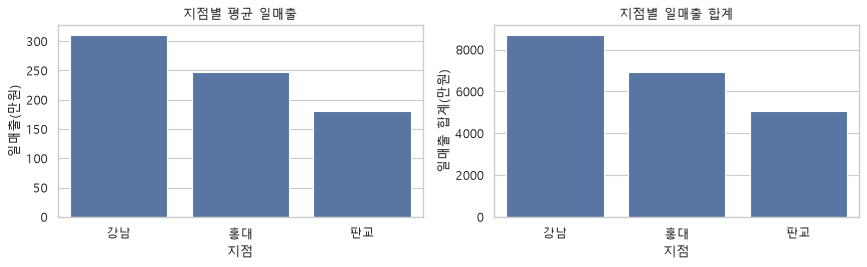

합계: [8717.0, 6904.0, 5082.0]


In [15]:
# 문제 27: matplotlib 3줄 = seaborn 한 줄 (지점별 평균 일매출)
# 왜 · 같은 그림을 더 짧게 그리는 seaborn의 장점을 비교하기 위해
평균 = sales.groupby("지점", sort=False)["일매출"].mean()       # 원본 계산 · 처음 나온 지점 순서
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))               # 문제 27 · 28 비교
sns.barplot(data=sales, x="지점", y="일매출", errorbar=None, ax=axes[0])  # 평균을 알아서 계산
axes[0].set(title="지점별 평균 일매출", ylabel="일매출(만원)")  # 제목 · 세로축 이름
print("막대 높이:", [round(float(p.get_height()), 2) for p in axes[0].patches])  # seaborn이 그린 값
print("groupby 평균:", 평균.round(2).tolist())                  # 같은 값 · 같은 순서


# 문제 28: barplot의 기본 estimator = 평균 → 합계로 바꾸면 28배
# 왜 · 기본값이 평균이라 합계가 필요하면 바꿔야 한다는 함정을 보이기 위해
sns.barplot(data=sales, x="지점", y="일매출", estimator="sum", errorbar=None, ax=axes[1])  # 합계
axes[1].set(title="지점별 일매출 합계", ylabel="일매출 합계(만원)")         # 제목
plt.tight_layout()                                                          # 간격 정리
plt.show()                                                                  # 화면에 띄움
print("합계:", sales.groupby("지점", sort=False)["일매출"].sum().tolist())  # 평균 × 28일

**결과** · 예측 정답은 같음 — 311.32

- `막대 높이: [311.32, 246.57, 181.5]` — seaborn이 그린 값 (강남 · 홍대 · 판교)
- `groupby 평균: [311.32, 246.57, 181.5]` — 직접 계산한 평균과 같음
- `합계: [8717.0, 6904.0, 5082.0]` — 합계 막대 = 평균 × 28일

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>sns.barplot</code> 기본</td><td>평균 + 신뢰구간 막대</td><td>집단 평균 비교</td></tr>
<tr><td><code>estimator="sum"</code></td><td>합계</td><td>총매출 비교</td></tr>
<tr><td><code>errorbar=None</code></td><td>오차 막대 없앰</td><td>평균만 보여 줄 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - seaborn 막대는 '개수'가 아니라 '평균'일 수 있음 → 무엇을 계산했는지 확인
> - 지점 순서는 데이터에 처음 나온 순서 · 원하는 순서는 `order=`

> ✅ **한 줄 정리** · sns.barplot은 x별로 y의 평균을 계산해 막대를 그리므로, 합계가 필요하면 estimator를 바꾸고 막대 높이를 groupby와 대조한다.

**딥러닝 코드에서는**

- 모델별 · fold별 점수표를 `sns.barplot(data=df, x="model", y="acc")` 한 줄로
- 오차 막대(errorbar)는 여러 seed의 퍼짐

### 5-2. `A` countplot · hue · style · `sns.countplot(order=)` · `sns.histplot(hue=, multiple=)` · `sns.scatterplot(style=)` <sub>원본 문제 29 · 30 · 31</sub>

> 🎯 **지점을 색(hue)과 모양(style) 둘 다로 나누면 무엇이 좋아지는가?**

💡 **쉽게 말하면**

- countplot은 **행 개수**를 셈 · 순서는 `order=`.
- hue는 색으로, style은 점 모양으로 집단을 나눔 · 흑백 인쇄에서도 구분됨.

**실행 흐름**

1. 요일별 개수 (월 ~ 일)
2. 전체 vs 지점별 쌓은 히스토그램
3. 산점도 hue + style · 점 크기 70

**먼저 예측** · 요일마다 데이터는 몇 행씩일까? — 답은 코드 실행 결과 아래에

요일별 개수: [12, 12, 12, 12, 12, 12, 12]


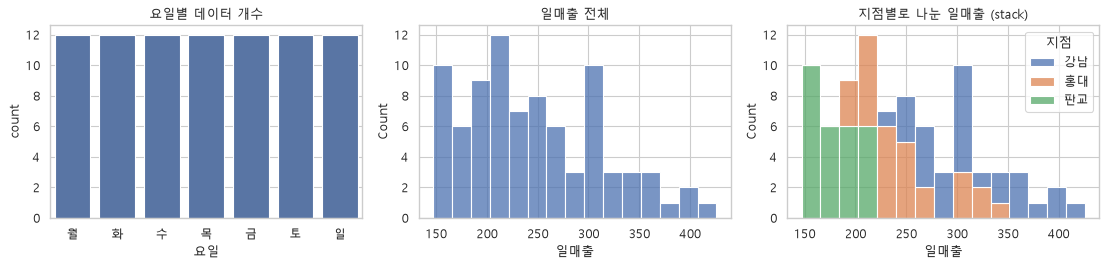

구분 표시 개수: 3


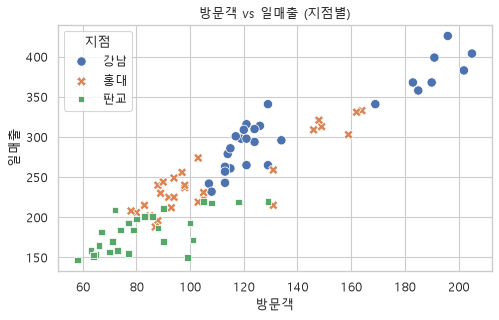

In [16]:
# 문제 29: 요일별 데이터 개수 · 월 ~ 일 순서 (order)
# 왜 · 범주 순서를 order로 고정해 요일이 뒤섞이지 않게 하기 위해
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))                           # 문제 29 · 30
sns.countplot(data=sales, x="요일", order=순서, ax=axes[0])                 # 행 개수를 셈
axes[0].set_title("요일별 데이터 개수")                                     # 제목
print("요일별 개수:", sales["요일"].value_counts().reindex(순서).tolist())  # 모두 12


# 문제 30: 왼쪽 = 전체 히스토그램 · 오른쪽 = 지점별 색 · 쌓기
# 왜 · 전체 분포와 지점별 분포를 한 번에 비교하기 위해
sns.histplot(data=sales, x="일매출", bins=15, ax=axes[1])  # 전체 84일
axes[1].set_title("일매출 전체")                           # 제목
sns.histplot(data=sales, x="일매출", hue="지점", multiple="stack", bins=15, ax=axes[2])  # 지점별 색
axes[2].set_title("지점별로 나눈 일매출 (stack)")          # 제목
plt.tight_layout()                                         # 간격 정리
plt.show()                                                 # 화면에 띄움


# 문제 31: 산점도에 지점을 색(hue)과 모양(style) 둘 다로 · 점 크기 70
# 왜 · 색을 구분하기 어려운 사람도 모양으로 구분할 수 있게 하기 위해
fig, ax = plt.subplots(figsize=(7, 4))                      # 칸 1개
# 2중 구분
sns.scatterplot(data=sales, x="방문객", y="일매출", hue="지점", style="지점", s=70, ax=ax)
ax.set_title("방문객 vs 일매출 (지점별)")                   # 제목
print("구분 표시 개수:", len(ax.get_legend().get_texts()))  # 범례 항목 = 지점 3개
plt.show()                                                  # 화면에 띄움

**결과** · 예측 정답은 12행씩 (3지점 × 4주)

- `요일별 개수: [12, 12, 12, 12, 12, 12, 12]` — 모든 요일이 같은 개수
- `구분 표시 개수: 3` — 범례에 지점 3개 (색 + 모양)
- 그림 · 쌓은 히스토그램에서 높은 매출 쪽은 강남, 낮은 쪽은 판교가 차지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>countplot</code></td><td>행 개수</td><td>범주별 데이터 수</td></tr>
<tr><td><code>hue=</code></td><td>색으로 집단 구분</td><td>2 ~ 5개 집단</td></tr>
<tr><td><code>multiple="stack"</code></td><td>집단을 위로 쌓음</td><td>전체 중 구성</td></tr>
<tr><td><code>style=</code></td><td>점 모양으로도 구분</td><td>흑백 · 색약 배려</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `order=`를 빼면 요일이 데이터에 처음 나온 순서로 나옴
> - hue 집단이 많으면 색이 비슷해져 구분이 어려움

> ✅ **한 줄 정리** · countplot은 행 개수를 order 순서로 세고, hue와 style은 집단을 색과 모양으로 나눠 한 그림에서 비교하게 한다.

**딥러닝 코드에서는**

- 클래스 분포 `sns.countplot(x=labels)` · 불균형 확인
- 임베딩 산점도 `hue=label`로 클래스별 무리 확인

### 5-3. `A` 박스플롯 + 실제 점 · 박스플롯 읽기 · `sns.boxplot` · `sns.stripplot(jitter=)` · `quantile` <sub>원본 문제 32 · 33</sub>

> 🎯 **박스플롯의 다섯 부분은 각각 무엇이고, 막대 대신 쓰면 무엇을 더 알 수 있는가?**

💡 **쉽게 말하면**

- 상자 안 선 = 중앙값 · 상자 아래 · 위 = Q1 · Q3 · 수염 = fence 안의 끝값 · 수염 밖 점 = 이상점 후보.
- 막대는 평균 하나, 박스는 **퍼짐과 튀는 값**까지 보여 줌.

**실행 흐름**

1. 연한 상자 + 진한 점 흩뿌리기
2. 강남의 Q1 · 중앙값 · Q3 · 수염 계산
3. 수염 밖 점 확인

**먼저 예측** · 강남점 28일 중 수염 밖 점이 있을까? — 답은 코드 실행 결과 아래에

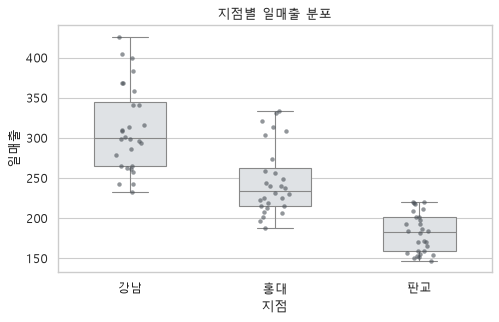

강남 | Q1 265.0 | 중앙값 299.5 | Q3 345.2
수염 232 ~ 426
수염 밖 점: []


In [17]:
# 문제 32: 지점별 일매출 박스플롯 + 실제 점 (stripplot)
# 왜 · 요약 상자 뒤에 숨은 실제 데이터 개수 · 위치도 함께 보기 위해
fig, ax = plt.subplots(figsize=(7, 4))                                    # 칸 1개
sns.boxplot(data=sales, x="지점", y="일매출", color="#dee2e6", width=0.5, ax=ax)  # 연한 상자
sns.stripplot(data=sales, x="지점", y="일매출", color="#495057", size=4,  # 진한 점
              alpha=0.6, jitter=True, ax=ax)                              # 반투명 · 좌우로 흩뿌림
ax.set_title("지점별 일매출 분포")                                        # 제목
plt.show()                                                                # 화면에 띄움


# 문제 33: 박스플롯 다섯 부분을 숫자로 확인 (강남점)
# 왜 · 그림에서 읽은 값이 실제 숫자와 맞는지 검증하기 위해
g = sales.loc[sales["지점"] == "강남", "일매출"]               # 강남 28일
q1, med, q3 = g.quantile([0.25, 0.5, 0.75])                    # 상자 아래 · 가운데 선 · 위
iqr = q3 - q1                                                  # 상자 길이
inside = g[(g >= q1 - 1.5 * iqr) & (g <= q3 + 1.5 * iqr)]      # 수염이 닿는 범위
print(f"강남 | Q1 {q1:.1f} | 중앙값 {med:.1f} | Q3 {q3:.1f}")  # 상자 아래 · 가운데 선 · 위
print(f"수염 {inside.min():.0f} ~ {inside.max():.0f}")         # fence 안의 끝값
print("수염 밖 점:", g[~g.isin(inside)].tolist())              # 이상점 후보

**결과** · 예측 정답은 없음 — 모두 232 ~ 426 안

- `강남 | Q1 265.0 | 중앙값 299.5 | Q3 345.2` — 상자 아래 · 가운데 선 · 위
- `수염 232 ~ 426` — fence 안의 가장 작은 값 · 큰 값
- `수염 밖 점: []` — 이상점 후보 없음
- 그림 · 강남 상자가 가장 높고 길며, 점을 뿌려 28일이 실제로 어디 있는지 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평균 막대</td><td>중심 하나</td><td>숫자 하나만 비교</td></tr>
<tr><td>박스플롯</td><td>중앙값 · IQR · 수염 · 후보</td><td>분포 비교</td></tr>
<tr><td>박스 + 점 (stripplot)</td><td>요약 + 원자료</td><td>표본이 작을 때 (수십 개)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점이 수천 개면 stripplot은 뭉개짐 → 박스 또는 violin
> - 수염 끝은 실제 최댓값이 아닐 수 있음 (fence 기준)

> ✅ **한 줄 정리** · 박스플롯은 중앙값 · Q1 · Q3 · 수염 · 이상점 후보로 분포를 요약하고, 점을 함께 뿌리면 실제 데이터가 어디 있는지도 보인다.

**딥러닝 코드에서는**

- seed 5개의 정확도를 모델별 박스 + 점으로
- 개념 설명은 통계 파일별 1의 4-3 · 7장

### 5-4. `A` 피벗 + 히트맵 · `pivot_table` · `sns.heatmap(annot=, fmt=)` <sub>원본 문제 34</sub>

> 🎯 **행 = 지점 · 열 = 요일 · 값 = 평균 일매출 표를 히트맵으로 그리려면?**

💡 **쉽게 말하면**

- 긴 표(84행)를 `pivot_table`로 **3 × 7 표**로 접음.
- 그 표를 그대로 `sns.heatmap`에 넣으면 칸마다 색 + 숫자.

**실행 흐름**

1. pivot_table(index, columns, values)
2. 열을 월 ~ 일로 · print로 확인
3. annot · fmt · 세로 글자 세우기

**먼저 예측** · 가장 진한 칸은 어느 지점 · 요일일까? — 답은 코드 실행 결과 아래에

요일      월      화      수      목      금      토      일
지점                                                 
강남  284.0  265.0  288.0  290.0  290.0  377.0  385.0
판교  173.0  166.0  184.0  180.0  176.0  195.0  196.0
홍대  236.0  226.0  214.0  216.0  238.0  280.0  316.0


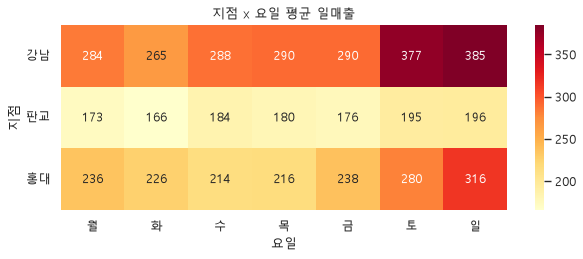

In [18]:
# 문제 34: 행 = 지점 · 열 = 요일 · 값 = 일매출 평균 → 먼저 print로 확인
# 왜 · 히트맵을 그리기 전에 표를 print로 먼저 확인하기 위해
pv = sales.pivot_table(index="지점", columns="요일", values="일매출", aggfunc="mean")  # 재구성
pv = pv[순서]       # 열을 월 ~ 일 순서로
print(pv.round(0))  # 히트맵 전에 눈으로 확인


fig, ax = plt.subplots(figsize=(9, 3))                        # 가로로 긴 칸
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax)  # 칸 안 숫자 · 소수점 없이
ax.tick_params(axis="y", rotation=0)                          # 누운 세로축 글자 세우기
ax.set_title("지점 x 요일 평균 일매출")                       # 제목
plt.show()                                                    # 화면에 띄움

**결과** · 예측 정답은 강남 · 일요일 (385)

- 피벗 표 · 3행(강남 · 판교 · 홍대) × 7열(월 ~ 일)
- `강남  284.0  265.0  288.0  290.0  290.0  377.0  385.0` — 강남은 토 · 일이 크게 높음
- `판교  173.0  166.0  184.0  180.0  176.0  195.0  196.0` — 판교는 주말 차이가 작음
- 그림 · 오른쪽 위(강남 토 · 일)가 가장 진하고 판교 줄은 전체가 연함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>pivot_table</code></td><td>긴 표 → 넓은 표 + 집계</td><td>행 × 열 조합의 평균</td></tr>
<tr><td><code>sns.heatmap(annot=True)</code></td><td>칸마다 색 + 숫자</td><td>패턴과 값을 함께</td></tr>
<tr><td><code>fmt=".0f"</code></td><td>칸 숫자 형식</td><td>소수점 없이</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 열 순서는 피벗 뒤 `pv[순서]`로 맞춰야 월 ~ 일
> - 히트맵 전에 피벗 결과를 print로 확인 (원본 지시)

> ✅ **한 줄 정리** · pivot_table로 행 × 열 표를 만든 뒤 sns.heatmap(annot=True, fmt=".0f")로 칸마다 색과 숫자를 보여 준다.

**딥러닝 코드에서는**

- 혼동 행렬 `sns.heatmap(cm, annot=True, fmt="d")`
- 하이퍼파라미터 탐색 결과(학습률 × 배치)를 피벗 히트맵으로

### 5-5. `B` seaborn + matplotlib · catplot과 ax · `ax.axhline` · `sns.catplot` · `warnings` <sub>원본 문제 35 · 36</sub>

> 🎯 **catplot에 `ax=`를 넘기면 어떻게 되고, 두 가지 고치는 방법은?**

💡 **쉽게 말하면**

- barplot 같은 **칸 단위 함수**는 ax를 받아 그 칸에 그림 → matplotlib으로 이어서 꾸밀 수 있음.
- catplot은 **그림판 단위 함수**라 그림판을 새로 만들고 ax는 쓰지 않음.

**실행 흐름**

1. barplot + 전체 평균 기준선
2. 원본 catplot(ax=ax) 실행 · 경고 확인
3. 방법 1 barplot · 방법 2 ax 빼기

**먼저 예측** · 원본처럼 `ax=ax`를 넘기면 ax에 막대가 그려질까? — 답은 코드 실행 결과 아래에

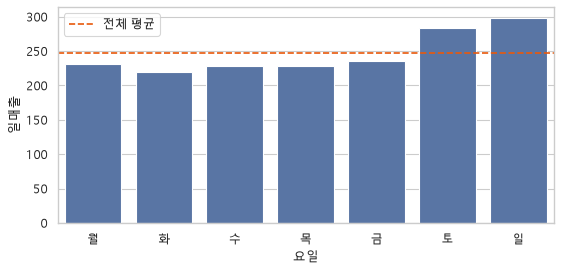

전체 평균 246.5만원
경고: catplot is a figure-level function and does not acce
ax의 막대: 0 | 새 그림판이 따로 생김: True


방법 1 · ax의 막대: 7


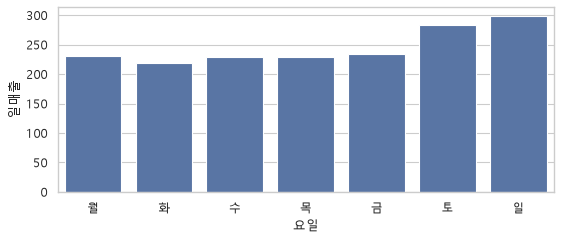

방법 2 결과: FacetGrid


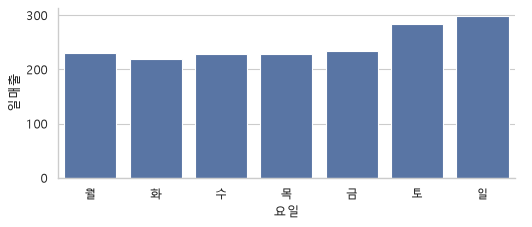

In [19]:
# 문제 35: seaborn으로 그리고 matplotlib으로 기준선 추가
# 왜 · seaborn 그림에도 ax를 받아 matplotlib 기능을 더할 수 있음을 보이기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))  # ax를 직접 만들어 seaborn에 넘김
sns.barplot(data=sales, x="요일", y="일매출", order=순서, errorbar=None, ax=ax)  # 요일별 평균
total = sales["일매출"].mean()                                                   # 전체 평균
ax.axhline(total, color="#e8590c", linestyle="--", label="전체 평균")            # 주황 점선 기준선
ax.legend()                                                                      # 범례
plt.show()                                                                       # 화면에 띄움
print(f"전체 평균 {total:.1f}만원")                                              # 기준선 높이


# 문제 36: catplot은 그림판(fig)을 스스로 만드는 '그림 단위' 함수 → ax를 쓰지 않음
# 왜 · 그림 단위 함수에 ax를 넘길 때 생기는 문제와 해결법을 확인하기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))              # 원본처럼 칸을 먼저 만듦
with warnings.catch_warnings(record=True) as caught:  # 원본 그대로 실행 · 경고 모으기
    warnings.simplefilter("always")                   # 경고를 빠짐없이 기록
    g0 = sns.catplot(data=sales, x="요일", y="일매출", kind="bar", order=순서,  # 원본 코드
                     errorbar=None, ax=ax)            # ax를 넘김
msg = [str(w.message) for w in caught if "figure-level" in str(w.message)][0]  # catplot 경고
print("경고:", msg[:52])                              # seaborn 0.13은 에러 대신 경고
print("ax의 막대:", len(ax.patches), "| 새 그림판이 따로 생김:", g0.figure is not fig)  # ax 무시
plt.close("all")                                      # 잘못 만든 그림 두 개 정리


# 방법 1: 칸 단위 함수(barplot)로 바꾸면 ax에 그림
# 왜 · 기존 칸 배치 안에 그리려면 칸 단위 함수를 써야 하기 때문에
fig, ax = plt.subplots(figsize=(8, 3))                                           # 칸 1개
sns.barplot(data=sales, x="요일", y="일매출", order=순서, errorbar=None, ax=ax)  # ax에 그림
print("방법 1 · ax의 막대:", len(ax.patches))                                    # 7개
plt.show()                                                                       # 화면에 띄움


# 방법 2: catplot을 그대로 쓰되 ax를 빼고 크기는 height · aspect로
# 왜 · 그림 단위 함수는 크기를 height · aspect로 정해야 하기 때문에
g = sns.catplot(data=sales, x="요일", y="일매출", kind="bar", order=순서,  # ax 없음
                errorbar=None, height=3, aspect=2.2)  # 세로 3인치 · 가로 = 세로 × 2.2
print("방법 2 결과:", type(g).__name__)               # FacetGrid (그림판 단위)
plt.show()                                            # 화면에 띄움

**결과** · 예측 정답은 안 그려짐 — ax의 막대 0개 · 새 그림판이 따로 생김

- `전체 평균 246.5만원` — 주황 점선 높이
- `경고: catplot is a figure-level function and does not acce` — seaborn 0.13은 에러 대신 경고 (원본은 TypeError)
- `ax의 막대: 0 | 새 그림판이 따로 생김: True` — 넘긴 ax는 무시됨
- `방법 1 · ax의 막대: 7` — 칸 단위 barplot은 ax에 그림
- `방법 2 결과: FacetGrid` — catplot은 그림판 단위 객체를 돌려줌

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>칸 단위 (<code>barplot</code> · <code>boxplot</code> …)</td><td>ax를 받음 · 반환도 Axes</td><td>subplots 칸에 넣을 때</td></tr>
<tr><td>그림판 단위 (<code>catplot</code> · <code>relplot</code> …)</td><td>그림판을 새로 만듦 · FacetGrid</td><td>col= · row=로 칸을 자동 분할</td></tr>
<tr><td><code>ax.axhline</code></td><td>seaborn 그림 위에 기준선</td><td>평균 · 목표값</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 경고는 에러가 아니라 실행이 계속됨 → 빈 칸이 남아도 모를 수 있음
> - catplot 크기는 figsize가 아니라 height · aspect

> ✅ **한 줄 정리** · barplot 같은 칸 단위 함수는 ax에 그리지만, catplot은 그림판 단위라 ax를 쓰지 않으므로 바꾸거나 ax를 뺀다.

**딥러닝 코드에서는**

- `sns.lineplot(..., ax=axes[0])`처럼 칸을 지정해 학습 곡선 대시보드
- 경고 메시지도 읽기 · 조용히 잘못된 그림이 나올 수 있음

---
## 6. 거짓말하는 그래프

> **이 장의 흐름**
>
> - 세로축을 0 ~ 100과 61 ~ 63으로 그려 인상이 얼마나 달라지는지 봄
> - 그다음 이중축의 문제와 파이 vs 가로 막대의 읽기 속도를 비교

<img src="images/st2_lie.png" alt="세로축 자르기로 1.4%p가 몇 배처럼 보임" width="989">

**파이프라인 위치** · ④ 전달 (속지 않고 속이지 않기)

### 6-1. `A` 세로축 자르기 · 의심하기 · `ax.set_ylim` <sub>원본 문제 37 · 40</sub>

> 🎯 **4.6점 막대가 4.2점 막대의 세 배 높이라면 가장 먼저 무엇을 확인하는가?**

💡 **쉽게 말하면**

- 막대 높이는 **세로축 시작점**부터 잼 · 시작점을 올리면 작은 차이가 커 보임.
- 그래서 막대그래프의 세로축은 0부터.

**실행 흐름**

1. 재구매율 4분기 · 축 0 ~ 100 vs 61 ~ 63
2. 실제 차이(%p)
3. 세 배로 보이게 한 축 시작점 역산

**먼저 예측** · 4.6 막대가 4.2 막대의 3배로 보이려면 세로축은 몇 점에서 시작했을까? — 답은 코드 실행 결과 아래에

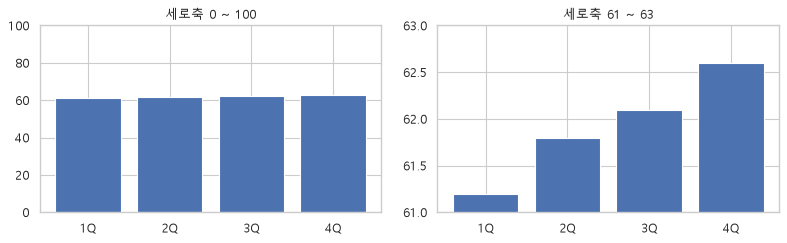

실제 차이: 1.4%p
실제 비율 1.10배 | 세로축 시작 4.0점이면 높이가 3배로 보임


In [20]:
# 문제 37: 같은 데이터, 세로축 0 ~ 100 vs 61 ~ 63
# 왜 · 축 범위만으로 차이가 과장되는 그래프를 직접 확인하기 위해
q = pd.DataFrame({"분기": ["1Q", "2Q", "3Q", "4Q"],       # 원본 데이터
                  "재구매율": [61.2, 61.8, 62.1, 62.6]})  # %
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))         # 가로 2칸
for ax, lim in zip(axes, [(0, 100), (61, 63)]):           # 축 범위만 다름
    ax.bar(q["분기"], q["재구매율"])                      # 같은 막대
    ax.set_ylim(*lim)                                     # 세로축
    ax.set_title(f"세로축 {lim[0]} ~ {lim[1]}")           # 칸 제목
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 화면에 띄움
diff = q["재구매율"].iloc[-1] - q["재구매율"].iloc[0]     # 4Q - 1Q
print(f"실제 차이: {diff:.1f}%p")                         # 1.4 퍼센트포인트


# 문제 40: 4.6점 막대가 4.2점의 세 배로 보이려면 축이 어디서 시작했나
# 왜 · 잘린 축이 만드는 착시를 숫자로 계산해 보기 위해
a, b = 4.6, 4.2               # 우리 회사 · B사
base = (a - 3 * b) / (1 - 3)  # (a - x) = 3 × (b - x)를 x에 대해 풂
print(f"실제 비율 {a / b:.2f}배 | 세로축 시작 {base:.1f}점이면 높이가 3배로 보임")  # 축부터 확인

**결과** · 예측 정답은 4.0점 — (4.6 - 4.0) ÷ (4.2 - 4.0) = 3

- `실제 차이: 1.4%p` — 61.2 → 62.6 · 오른쪽 그림에서는 몇 배처럼 보임
- `실제 비율 1.10배 | 세로축 시작 4.0점이면 높이가 3배로 보임` — 문제 40 · 축 시작점부터 확인
- 그림 · 왼쪽(0 ~ 100)은 네 막대가 거의 같고, 오른쪽(61 ~ 63)은 4Q가 1Q의 몇 배처럼 보임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>막대 · 축 0부터</td><td>높이 = 값</td><td>막대그래프 기본</td></tr>
<tr><td>막대 · 축 잘림</td><td>작은 차이가 부풀려짐</td><td>쓰지 않음</td></tr>
<tr><td>꺾은선 · 축 잘림</td><td>변화 폭을 자세히 봄</td><td>선은 0부터 아니어도 됨 (범위 표시)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - %와 %p를 구분 · 61.2% → 62.6%는 1.4%p 증가 (약 2.3% 증가)
> - 남의 그래프를 볼 때는 축 범위 · 단위부터

> ✅ **한 줄 정리** · 막대 높이는 세로축 시작점부터 재므로 축을 자르면 작은 차이가 몇 배로 보이며, 막대그래프는 0부터 시작하고 남의 그래프는 축부터 확인한다.

**딥러닝 코드에서는**

- 정확도 0.981 vs 0.983을 0.98 ~ 0.99 축으로 그리면 큰 차이처럼 보임
- 모델 비교 그림에는 축 범위와 함께 실제 차이를 숫자로

### 6-2. `B` 이중축 · 파이 vs 가로 막대 · `ax1.twinx()` · `ax.pie` <sub>원본 문제 38 · 39</sub>

> 🎯 **매출과 방문객을 이중축으로 그리면 무엇이 문제이고, 파이와 막대 중 무엇이 빨리 읽히는가?**

💡 **쉽게 말하면**

- 이중축은 두 축 범위를 마음대로 정할 수 있어 **두 선이 붙어 보이게** 만들 수 있음.
- 콜드브루 180 vs 샌드위치 130은 막대 길이로는 바로, 파이 조각으로는 비교가 어려움.

**실행 흐름**

1. `twinx`로 오른쪽 축 추가
2. 두 축 범위 출력 · 문제점 2줄
3. 파이 vs 오름차순 가로 막대

**먼저 예측** · 이중축에서 두 선이 거의 겹쳐 보이는 것은 실제로 같은 크기라서일까? — 답은 코드 실행 결과 아래에

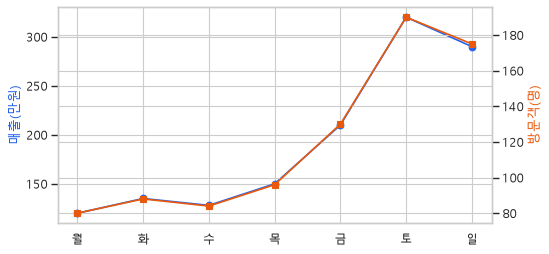

왼쪽 축: (110, 330) | 오른쪽 축: (74, 196)


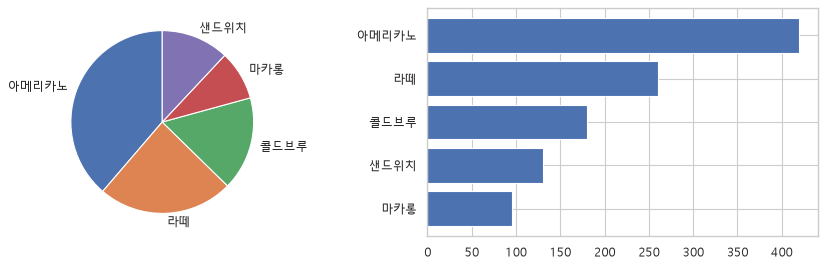

콜드브루 180 vs 샌드위치 130


In [21]:
# 문제 38: 이중축 (매출 만원 + 방문객 명)
# 왜 · 단위가 다른 두 값을 한 그림에 그릴 때의 방법과 주의점을 보기 위해
fig, ax1 = plt.subplots(figsize=(7, 3.5))                                   # 왼쪽 축
ax1.plot(week["요일"], week["매출"], color="#2563eb", marker="o")           # 매출
ax1.set_ylabel("매출(만원)", color="#2563eb")                               # 왼쪽 축 이름
ax2 = ax1.twinx()  # 같은 가로축 · 오른쪽에 새 세로축
ax2.plot(week["요일"], week["방문객"], color="#e8590c", marker="s")         # 방문객
ax2.set_ylabel("방문객(명)", color="#e8590c")                               # 오른쪽 축 이름
plt.show()                                                                  # 화면에 띄움
print("왼쪽 축:", tuple(round(v) for v in ax1.get_ylim()), "| 오른쪽 축:",  # 축마다 범위가 다름
      tuple(round(v) for v in ax2.get_ylim()))  # 범위를 바꾸면 두 선의 겹침이 달라짐
# 문제점 1: 두 축의 범위를 마음대로 정할 수 있어 '같이 움직인다'는 인상을 만들 수 있음
# 문제점 2: 어느 선이 어느 축인지 헷갈림 → 칸을 나누는 것이 기본 (문제 20)


# 문제 39: 파이 vs 정렬한 가로 막대 — 콜드브루와 샌드위치 중 어느 쪽이 더 많은가
# 왜 · 비슷한 크기의 항목은 파이보다 정렬한 막대에서 비교가 쉽다는 것을 보이기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # 가로 2칸
axes[0].pie(menu["판매량"], labels=menu["메뉴"], startangle=90)  # 조각 크기로 비교
m_asc = menu.sort_values("판매량")                 # barh는 아래부터 → 오름차순이면 1등이 맨 위
axes[1].barh(m_asc["메뉴"], m_asc["판매량"])       # 길이로 비교
plt.tight_layout()                                 # 간격 정리
plt.show()                                         # 화면에 띄움
cb, sw = menu.set_index("메뉴").loc[["콜드브루", "샌드위치"], "판매량"]  # 두 메뉴
print(f"콜드브루 {cb} vs 샌드위치 {sw}")           # 막대 길이로는 바로 · 파이 조각으로는 어려움

**결과** · 예측 정답은 아님 — 왼쪽 축(110 ~ 330)과 오른쪽 축(74 ~ 196)의 범위가 우연히 맞았을 뿐

- `왼쪽 축: (110, 330) | 오른쪽 축: (74, 196)` — 축마다 범위가 달라 겹침은 축이 만든 것
- `콜드브루 180 vs 샌드위치 130` — 막대에서는 바로 · 파이에서는 조각을 비교해야 함
- 그림 · 이중축 두 선이 거의 포개지고, 파이는 조각이 비슷해 보이며 막대는 길이 차이가 뚜렷함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>이중축 <code>twinx</code></td><td>단위 다른 두 선을 한 칸에 · 범위 조작 가능</td><td>꼭 필요할 때만 · 축 색 구분</td></tr>
<tr><td>칸 나누기</td><td>단위마다 칸</td><td>기본 (문제 20)</td></tr>
<tr><td>파이</td><td>전체 중 비중</td><td>항목 4 ~ 5개 이하</td></tr>
<tr><td>정렬한 가로 막대</td><td>길이 비교 · 순위</td><td>항목 비교 대부분</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 이중축은 상관이 있어 보이게 만들기 쉬움 → 칸을 나누기
> - 파이는 항목이 많거나 비슷하면 쓰지 않기

> ✅ **한 줄 정리** · 이중축은 두 축 범위를 조절해 관계를 꾸며낼 수 있어 칸 나누기가 기본이고, 항목 비교는 파이보다 정렬한 막대가 빨리 정확하게 읽힌다.

**딥러닝 코드에서는**

- loss와 learning rate를 한 칸에 이중축으로 그릴 때는 축 색 · 이름을 분명히
- 클래스 비율 발표는 파이 대신 정렬 막대

---
## 7. 종합 실습 · 질문부터 발표용 한 장까지

> **이 장의 흐름**
>
> - 1 ~ 6장 문법을 원본 종합 문제 3개에 그대로 적용
> - 숫자로 확인한 사실을 제목에 쓰고 파일로 저장

<img src="images/st2_practice.png" alt="질문 → 계산 → 그림 → 사실 제목 → 저장" width="793">

**파이프라인 위치** · ② 요약 → ③ 해석 → ④ 전달

> 🎯 **주말에는 손님이 늘어난 만큼 매출도 늘어나는가?**

💡 **쉽게 말하면**

- **질문 → 설계 → 계산 → 그림 → 제목 → 저장** 순서.
- 객단가(일매출 ÷ 방문객)를 만들면 '손님 수'와 '한 명당 매출'을 나눠 볼 수 있음.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>객단가 열 만들기 · 요일별 평균</td><td>2-2 · 5-1</td></tr>
<tr><td>2</td><td>평일 vs 주말 객단가 · 주말 2칸 강조</td><td>4-2</td></tr>
<tr><td>3</td><td>지점별 요일 흐름(hue) + 피벗 히트맵</td><td>5-2 · 5-4</td></tr>
<tr><td>4</td><td>주말 ÷ 평일 배율 비교</td><td>4-3</td></tr>
<tr><td>5</td><td>1등 지점만 강조한 가로 막대 · 테두리 정리</td><td>2-2 · 4-2</td></tr>
<tr><td>6</td><td>사실 제목 · 저장</td><td>4-3</td></tr>
</tbody></table>

**먼저 예측** · 주말 객단가는 평일보다 높을까, 낮을까? — 답은 코드 실행 결과 아래에

평일 객단가 2.41만원 | 주말 객단가 1.95만원 | 주말이 19% 낮음


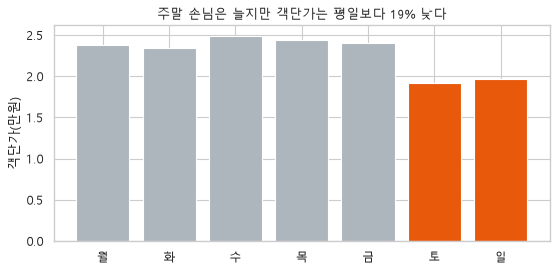

In [22]:
# 문제 41: 주말에는 손님이 늘어난 만큼 매출도 늘어나는가? → 객단가 = 일매출 ÷ 방문객
# 왜 · 매출 증가가 손님 수 때문인지 객단가 때문인지 나눠 보기 위해
sales["객단가"] = sales["일매출"] / sales["방문객"]            # 손님 1명당 매출(만원)
by_day = sales.groupby("요일")["객단가"].mean().reindex(순서)  # 요일별 평균 객단가
is_weekend = sales["요일"].isin(["토", "일"])                  # 주말 표시
wd, we = sales.loc[~is_weekend, "객단가"].mean(), sales.loc[is_weekend, "객단가"].mean()  # 평균
print(f"평일 객단가 {wd:.2f}만원 | 주말 객단가 {we:.2f}만원 | 주말이 {1 - we / wd:.0%} 낮음")  # 답


fig, ax = plt.subplots(figsize=(8, 3.5))                                      # 칸 1개
colors = ["#e8590c" if d in ("토", "일") else "#adb5bd" for d in 순서]        # 주말 2칸 강조
ax.bar(순서, by_day.values, color=colors)                                     # 요일별 평균 객단가
ax.set_ylabel("객단가(만원)")                                                 # 단위
ax.set_title(f"주말 손님은 늘지만 객단가는 평일보다 {1 - we / wd:.0%} 낮다")  # 발견한 사실
plt.show()                                                                    # 화면에 띄움

**실행 흐름**

1. 지점별 요일 흐름을 꺾은선으로 (왼쪽 칸)
2. 지점 × 요일 평균을 피벗해 히트맵으로 (오른쪽 칸)
3. 두 칸을 나란히 출력

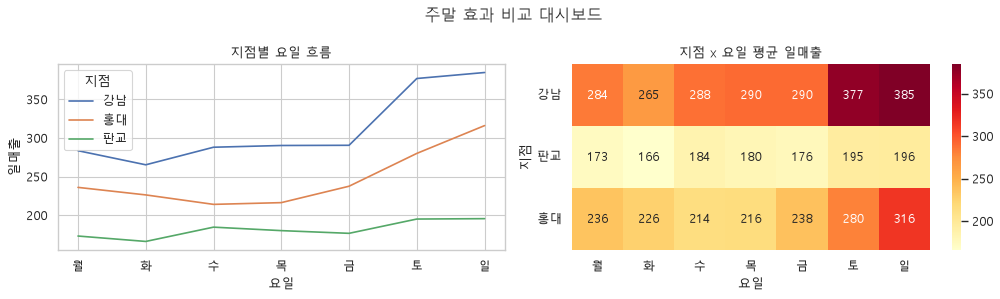

주말 매출 ÷ 평일 매출: {'강남': 1.34, '판교': 1.11, '홍대': 1.32}


In [23]:
# 문제 42: 주말 효과는 세 지점에서 똑같이 나타나는가?
# 왜 · 전체 평균에 가려진 지점별 차이를 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))                             # 가로 2칸
sns.lineplot(data=sales, x="요일", y="일매출", hue="지점", errorbar=None, ax=axes[0])  # 지점별 선
axes[0].set_title("지점별 요일 흐름")                                         # 칸 제목
pv2 = sales.pivot_table(index="지점", columns="요일", values="일매출")[순서]  # 지점 x 요일 평균
sns.heatmap(pv2, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1])            # 히트맵
axes[1].tick_params(axis="y", rotation=0)                                     # 세로 글자 세우기
axes[1].set_title("지점 x 요일 평균 일매출")                                  # 칸 제목
fig.suptitle("주말 효과 비교 대시보드")                                       # 전체 제목
plt.tight_layout()                                                            # 간격 정리
plt.show()                                                                    # 화면에 띄움
# 주말 ÷ 평일
lift = (pv2[["토", "일"]].mean(axis=1) / pv2[list("월화수목금")].mean(axis=1)).round(2)
print("주말 매출 ÷ 평일 매출:", lift.to_dict())                               # 지점마다 배율 비교

**실행 흐름**

1. 지점별 평균 일매출 계산
2. 1등만 강조한 막대 · 테두리 정리 · 발견을 담은 제목
3. 그림 출력 · 파일 저장

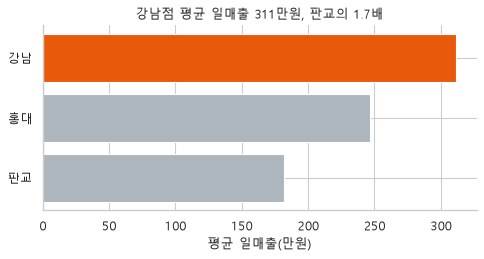

1등: 강남 | 저장: True


In [24]:
# 문제 43: 사장님께 드릴 한 장 · 1등만 강조 · 테두리 정리 · 발견한 사실 제목 · 저장
# 왜 · 결론 하나가 바로 보이도록 강조 · 정리 · 제목을 모두 적용하기 위해
avg = sales.groupby("지점")["일매출"].mean().sort_values()          # 오름차순 → barh 맨 위가 1등
best = avg.idxmax()                                                 # 1등 지점
fig, ax = plt.subplots(figsize=(7, 3))                              # 칸 1개
bar_colors = ["#e8590c" if k == best else "#adb5bd" for k in avg.index]  # 1등만 주황
ax.barh(avg.index, avg.values, color=bar_colors)                    # 가로 막대
ax.spines[["top", "right"]].set_visible(False)                      # 위 · 오른쪽 테두리 제거
ax.set_ylabel("")                                                   # 지점 이름이 이미 있으므로 비움
ax.set_xlabel("평균 일매출(만원)")                                  # 단위
# 사실
ax.set_title(f"{best}점 평균 일매출 {avg.max():.0f}만원, 판교의 {avg.max() / avg['판교']:.1f}배")
fig.savefig(SAVE / "지점별매출.png", dpi=150, bbox_inches="tight")  # 해상도 150 · 잘림 없이
plt.show()                                                          # 화면에도 띄움
print("1등:", best, "| 저장:", (SAVE / "지점별매출.png").exists())  # 결과 확인

**결과** · 예측 정답은 낮음 — 평일 2.41만원 → 주말 1.95만원 (19% 낮음)

- `평일 객단가 2.41만원 | 주말 객단가 1.95만원 | 주말이 19% 낮음` — 손님은 늘지만 한 명당 매출은 줄어듦
- `주말 매출 ÷ 평일 매출: {'강남': 1.34, '판교': 1.11, '홍대': 1.32}` — 판교만 주말 효과가 작음
- `1등: 강남 | 저장: True` — 실습파일/지점별매출.png
- 그림 · 마지막 그림은 강남 막대만 주황 · 제목에 강남 평균과 판교 대비 배율

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>방문객만 보기</td><td>주말에 크게 늘어남</td><td>손님 수 질문</td></tr>
<tr><td>객단가 보기</td><td>주말에 오히려 낮음</td><td>'매출도 그만큼 느는가' 질문</td></tr>
<tr><td>지점별 비교</td><td>판교는 주말 효과가 작음</td><td>지점별 운영 전략</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 지점마다 주말은 8일뿐 · 배율 차이는 잡음일 수 있음
> - 발표용 그림은 강조 1개 · 사실 제목 · 단위 · 저장까지 확인

> ✅ **한 줄 정리** · 질문을 먼저 정하고 필요한 열(객단가)을 만들어 계산한 뒤, 강조색과 발견한 사실 제목을 단 그림을 저장하면 한 장으로 답할 수 있다.

**딥러닝 코드에서는**

- 실험 보고서 그림 = 질문 · 사실 제목 · 강조 · 저장의 같은 순서
- 새 지표(객단가처럼)를 만들어 보는 것 = 특성 공학

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. fig · ax · set_</td><td><code>ax.title()</code> 에러를 <code>set_title</code>로 고치고 전체 제목은 <code>fig.suptitle</code></td><td>1장</td></tr>
<tr><td>2. 질문 → 그림 4종</td><td>변화 = 꺾은선 · 비교 = 막대 · 관계 = 산점도(상관 0.920) · 분포 = 히스토그램</td><td>2장</td></tr>
<tr><td>3. 여러 칸 비교</td><td><code>axes[1, 1]</code> · <code>sharey=True</code>로 세로축 (0.0, 7.3) 공유 · ndarray 에러 고침</td><td>3장</td></tr>
<tr><td>4. 전달용 그림</td><td>금요일만 강조 · 화살표 · 저장 · '토요일이 월 ~ 목의 2.4배' 제목</td><td>4장 · 7장</td></tr>
<tr><td>5. seaborn · 속이는 그래프</td><td>barplot = 평균(311.32) · catplot은 ax 무시 · 축 자르기로 1.4%p가 몇 배처럼</td><td>5 · 6장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td><code>fig, ax = plt.subplots()</code></td><td>그림판 · 칸 · set_</td><td>학습 곡선 틀</td></tr>
<tr><td><code>A</code></td><td>질문 → 그림 4종</td><td>변화 · 비교 · 관계 · 분포</td><td>loss 선 · 클래스 막대</td></tr>
<tr><td><code>A</code></td><td><code>axes[i]</code> · <code>sharey</code></td><td>칸 고르기 · 축 맞추기</td><td>loss · acc 나란히</td></tr>
<tr><td><code>A</code></td><td>강조 · 사실 제목 · <code>savefig</code></td><td>색 목록 · bbox_inches</td><td>실험 기록 그림</td></tr>
<tr><td><code>A</code></td><td>seaborn 집계</td><td>barplot = 평균 · hue · heatmap</td><td>혼동 행렬</td></tr>
<tr><td><code>A</code></td><td>속이는 그래프</td><td>축 0부터 · 이중축 주의</td><td>모델 비교 그림</td></tr>
<tr><td><code>B</code></td><td>catplot vs barplot</td><td>그림판 단위 vs 칸 단위</td><td>FacetGrid</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · plt 방식과 ax 방식의 차이는?
- **1-2** · `ax.title("…")`이 에러인 이유는?
- **1-3** · 전체 제목은 무엇으로 붙이는가?
- **2-1** · 분포 질문에 맞는 그림은?
- **2-2** · barh에서 1등을 맨 위로 하려면?
- **2-3** · 산점도로 말할 수 있는 것은?
- **2-4** · 막대와 히스토그램의 가로축 차이는?
- **3-1** · 2행 2열의 오른쪽 아래 칸은?
- **3-2** · 세 칸의 세로축을 맞추려면?
- **3-3** · ndarray에 set_title 에러는 왜?
- **4-1** · 격자를 막대 뒤로 보내려면?
- **4-2** · 하나만 강조하려면?
- **4-3** · 저장할 때 잘림을 막는 인자는?
- **5-1** · sns.barplot의 기본 계산은?
- **5-2** · hue와 style의 차이는?
- **5-3** · 박스플롯 수염 밖 점은?
- **5-4** · 긴 표를 행 × 열 표로 바꾸는 함수는?
- **5-5** · catplot에 ax를 넘기면?
- **6-1** · 막대그래프 세로축은 어디서 시작해야 하는가?
- **6-2** · 이중축의 문제는?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 월 · 화 · 수 매출(120 · 135 · 128)로 막대를 그리되 가장 높은 요일만 주황, 세로축 0 ~ 150
2. 막대 개수와 세로축 범위를 출력하고, 가장 높은 요일 이름을 코드로 찾아 출력

In [25]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 문제 13을 bins 10으로 다시 그리면 빈 구간은 몇 개일까? 코드로 확인
2. 문제 28을 `estimator="max"`로 바꾸면 강남 막대는 무슨 값인가?
3. 문제 37에서 세로축을 60 ~ 64로 그리면 4Q 막대는 1Q 막대의 몇 배 높이로 보이는가?

In [26]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 현재 그림판에 바로 vs 그림판 · 칸을 변수로 받아 그 칸에
- **1-2** · `ax.title`은 Text 객체 · 함수는 `set_title`
- **1-3** · `fig.suptitle()`
- **2-1** · 히스토그램
- **2-2** · `invert_yaxis()` 또는 오름차순으로 넣기
- **2-3** · 경향(상관)까지 · 원인은 아님
- **2-4** · 범주 vs 수치 구간
- **3-1** · `axes[1, 1]`
- **3-2** · `plt.subplots(..., sharey=True)`
- **3-3** · 칸이 여러 개라 axes가 배열 · `axes[0]`로 고름
- **4-1** · `ax.set_axisbelow(True)`
- **4-2** · 막대마다 색 목록을 만들어 한 번에 그림
- **4-3** · `bbox_inches="tight"`
- **5-1** · 평균 (estimator로 변경)
- **5-2** · 색 vs 점 모양으로 집단 구분
- **5-3** · 이상점 후보
- **5-4** · `pivot_table`
- **5-5** · ax를 무시하고 새 그림판 (0.13은 경고)
- **6-1** · 0
- **6-2** · 축 범위로 관계를 꾸며낼 수 있음 · 칸 나누기가 기본

#### 코드 문제 답

```python
d = pd.DataFrame({"요일": ["월", "화", "수"], "매출": [120, 135, 128]})
fig, ax = plt.subplots()
ax.bar(d["요일"], d["매출"], color=["#adb5bd", "#e8590c", "#adb5bd"])
ax.set_ylim(0, 150)
print(len(ax.patches), tuple(float(v) for v in ax.get_ylim()))  # 3 (0.0, 150.0)
print(d.loc[d["매출"].idxmax(), "요일"])  # 화
plt.close(fig)
```

#### 변형 문제 답

*문제 → 답*

- **1** · `(np.histogram(sales["일매출"], bins=10)[0] == 0).sum()` → 0개
- **2** · 426 — 강남 28일 중 가장 큰 일매출 (홍대 333 · 판교 220)
- **3** · (62.6 - 60) ÷ (61.2 - 60) = 2.17배

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) seaborn 막대를 '지점별 데이터 개수'라고 읽음</td><td>barplot이 무엇을 계산하는지 확인 안 함</td><td>barplot = 평균 · 개수는 countplot</td><td>막대 높이를 groupby와 대조했나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. matplotlib의 Figure와 Axes는 어떻게 다른가요?**
> - Figure는 그림판 전체이고 Axes는 그 안의 그래프 칸 하나입니다.
> - 칸마다 제목과 축은 ax.set_title 같은 메서드로, 전체 제목은 fig.suptitle로 붙이며, 여러 칸이면 axes 배열에서 칸을 골라 그립니다.

**Q2. 그래프로 사람을 속이는 대표적인 방법과 대처는?**
> - 막대그래프의 세로축을 0이 아닌 곳에서 시작해 작은 차이를 크게 보이게 하거나, 이중축 범위를 조절해 두 변수가 같이 움직이는 것처럼 보이게 하는 방법이 있습니다.
> - 그래서 그래프를 볼 때는 축 범위와 단위부터 확인하고, 만들 때는 막대 축을 0부터 시작하고 단위가 다르면 칸을 나눕니다.

**Q3. seaborn barplot의 막대는 무엇을 뜻하나요?**
> - 기본값은 x 그룹별 y의 평균이고 오차 막대는 신뢰구간입니다.
> - 합계가 필요하면 estimator를 바꾸고, 행 개수는 countplot으로 셉니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>plt.subplots(행, 열, figsize=, sharey=)</code></td><td>matplotlib</td><td>그림판 + 칸</td><td>1-1 · 3-1 · 3-2</td></tr>
<tr><td><code>ax.set_title · set_xlabel · set(...)</code></td><td>matplotlib Axes</td><td>칸 꾸미기</td><td>1-2 <code>ax.set_title("요일별 매출")</code></td></tr>
<tr><td><code>fig.suptitle</code></td><td>matplotlib Figure</td><td>전체 제목</td><td>1-3 · 3-1</td></tr>
<tr><td><code>ax.plot · bar · barh · scatter · hist</code></td><td>matplotlib Axes</td><td>그림 4종</td><td>2-1 ~ 2-4</td></tr>
<tr><td><code>ax.invert_yaxis</code></td><td>matplotlib Axes</td><td>가로 막대 1등 위로</td><td>2-2</td></tr>
<tr><td><code>ax.annotate(xy, xytext)</code></td><td>matplotlib Axes</td><td>화살표 주석</td><td>4-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>fig.savefig(dpi=, bbox_inches=)</code></td><td>matplotlib Figure</td><td>파일 저장</td><td>4-3 <code>SAVE / "금요일매출.png"</code></td></tr>
<tr><td><code>sns.barplot(estimator=, errorbar=)</code></td><td>seaborn</td><td>그룹 평균 · 합계 막대</td><td>5-1</td></tr>
<tr><td><code>sns.countplot · histplot · scatterplot</code></td><td>seaborn</td><td>개수 · 분포 · 관계 (hue · style)</td><td>5-2</td></tr>
<tr><td><code>sns.boxplot + stripplot</code></td><td>seaborn</td><td>박스 + 실제 점</td><td>5-3</td></tr>
<tr><td><code>pivot_table</code> → <code>sns.heatmap</code></td><td>pandas · seaborn</td><td>행 × 열 표를 색으로</td><td>5-4</td></tr>
<tr><td><code>sns.catplot(height=, aspect=)</code></td><td>seaborn</td><td>그림판 단위 그래프</td><td>5-5</td></tr>
<tr><td><code>ax1.twinx()</code></td><td>matplotlib Axes</td><td>이중축</td><td>6-2</td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td><code>fig, ax = plt.subplots()</code>로 시작</td><td>plt와 ax 방식을 한 칸에 섞기</td></tr>
<tr><td>세로축 이름에 단위 · 막대 축은 0부터</td><td>축을 잘라 작은 차이를 크게</td></tr>
<tr><td>여러 칸 비교는 <code>sharey=True</code></td><td>칸마다 다른 눈금으로 높이 비교</td></tr>
<tr><td>제목에 계산으로 확인한 발견한 사실</td><td>'요일별 매출'처럼 내용만 적기</td></tr>
<tr><td>seaborn 막대 높이를 groupby와 대조</td><td>barplot을 개수로 읽기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>plt.title</code> vs <code>ax.set_title</code></td><td>plt 방식 vs ax 방식</td><td>ax 방식이 기본</td></tr>
<tr><td><code>ax</code> vs <code>axes</code></td><td>칸 1개 vs 칸 배열</td><td>여러 칸이면 <code>axes[i]</code></td></tr>
<tr><td>막대 vs 히스토그램</td><td>범주 vs 수치 구간</td><td>가로축으로 구분</td></tr>
<tr><td><code>barplot</code> vs <code>countplot</code></td><td>y의 평균 vs 행 개수</td><td>무엇을 셌는지 확인</td></tr>
<tr><td><code>barplot</code> vs <code>catplot</code></td><td>칸 단위 vs 그림판 단위</td><td>ax가 필요하면 barplot</td></tr>
<tr><td>이중축 vs 칸 나누기</td><td>한 칸 두 축 vs 단위마다 칸</td><td>칸 나누기가 기본</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 고장 난 코드 3개(문제 4 · 19 · 36)를 보지 않고 고치기</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>7장 종합 실습을 빈 셀에 직접 다시 짜기</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>통계 파일별 1과 함께 ✅ 줄만 읽기 · 그래프 고르기 표 다시 보기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `coffee_q.ipynb`의 준비 셀 3개 · Part A ~ G 문제 43개 (빈 코드 칸 · 서술 칸 · 고장 난 코드)
- 문제를 주제별로 2 ~ 5개씩 묶어 섹션 하나로 · 모든 문제에 모범 답안 코드 또는 서술 답을 출력으로 남김
- 원본의 Colab 글꼴 설치는 맑은 고딕으로 · 문제 36의 TypeError는 실제 버전(seaborn 0.13) 동작으로 고쳐 설명
- 모든 코드는 실행한 출력과 함께 저장 · 형식 v2.1 (FORMAT_V2.md 1 ~ 7절)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>준비 [1/3] · [2/3] · [3/3]</td><td>글꼴 설치 · 라이브러리 · week · menu · sales</td><td>0 준비</td></tr>
<tr><td>Part A 문제 1 ~ 6</td><td>plt vs ax · 꾸미기 · 고장 코드 · fig와 ax · 한글</td><td>1-1 · 1-2 · 1-3</td></tr>
<tr><td>Part B 문제 7 ~ 8</td><td>질문과 그림 짝 · 꺾은선</td><td>2-1</td></tr>
<tr><td>Part B 문제 9 · 10 · 15</td><td>막대 정렬 · 가로 막대 · 잘못 고른 그래프</td><td>2-2</td></tr>
<tr><td>Part B 문제 11 · 12</td><td>산점도 · 해석</td><td>2-3</td></tr>
<tr><td>Part B 문제 13 · 14</td><td>히스토그램 bins · 막대와 차이</td><td>2-4</td></tr>
<tr><td>Part C 문제 16 ~ 20</td><td>가로 2칸 · 대시보드 · sharey · axes 에러 · 겹칠까</td><td>3-1 · 3-2 · 3-3</td></tr>
<tr><td>Part D 문제 21 ~ 26</td><td>스타일 · 눈금 · 강조 · 화살표 · 저장 · 제목</td><td>4-1 · 4-2 · 4-3</td></tr>
<tr><td>Part E 문제 27 ~ 31</td><td>barplot · estimator · countplot · hue · style</td><td>5-1 · 5-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>Part E 문제 32 ~ 36</td><td>박스 + 점 · 박스 읽기 · 피벗 히트맵 · 기준선 · catplot</td><td>5-3 · 5-4 · 5-5</td></tr>
<tr><td>Part F 문제 37 ~ 40</td><td>축 자르기 · 이중축 · 파이 vs 막대 · 의심하기</td><td>6-1 · 6-2</td></tr>
<tr><td>Part G 문제 41 ~ 43</td><td>객단가 · 주말 효과 대시보드 · 발표용 한 장</td><td>7 종합 실습</td></tr>
</tbody></table>

### 전체 코드

1 ~ 7장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 plt · ax 방식
2. 1-2 제목 · 축 이름 · 고장 난 코드
3. 1-3 fig vs ax · 한글 글꼴

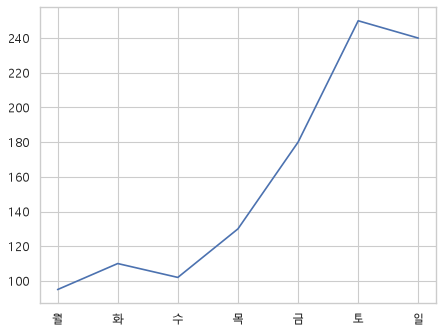

Figure Axes [7.0, 4.0]


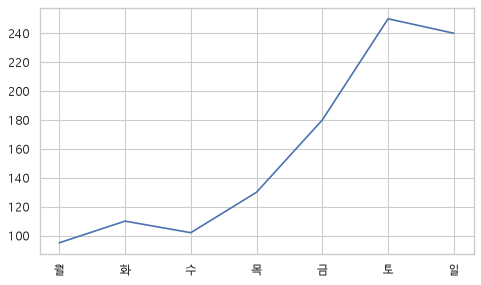

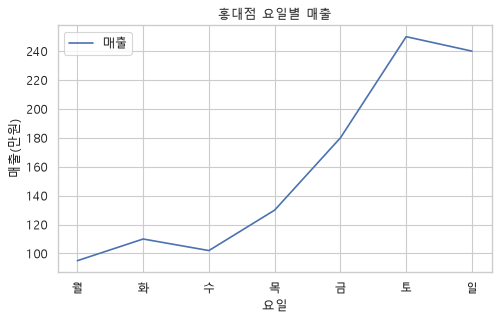

에러: 'Text' object is not callable
고친 뒤 제목: 요일별 매출


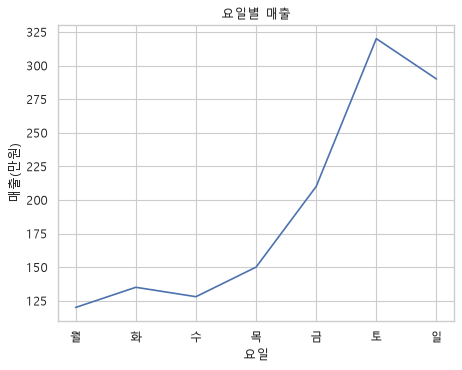

fig 안의 칸 수: 2 | 전체 제목: 강남점 일주일


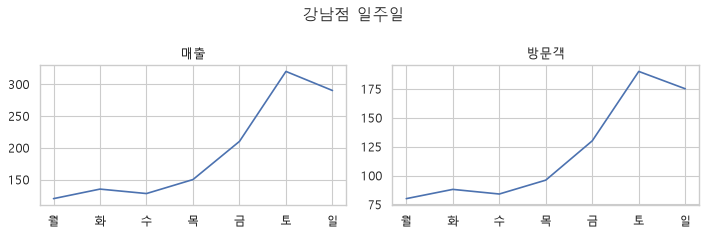

맑은 고딕 설치: True


In [27]:
# ---------- 1-1 ----------
# 문제 1: 리스트 → 꺾은선 (plt 방식)
# 왜 · 가장 짧은 plt 방식으로 그래프의 기본 흐름을 먼저 익히기 위해
요일7 = ["월", "화", "수", "목", "금", "토", "일"]  # 가로축 이름
매출2 = [95, 110, 102, 130, 180, 250, 240]          # 홍대점 매출
plt.plot(요일7, 매출2)                              # 현재 그림판에 선 1개
plt.show()                                          # 화면에 띄움


# 문제 2: 같은 그림을 ax 방식으로 · figsize 7 × 4
# 왜 · 칸이 여러 개일 때 필요한 ax 방식을 같은 그림으로 비교하기 위해
fig, ax = plt.subplots(figsize=(7, 4))  # 그림판 fig · 그릴 칸 ax
ax.plot(요일7, 매출2)                   # ax에 직접 그림
print(type(fig).__name__, type(ax).__name__, fig.get_size_inches().tolist())  # 무엇인지 · 크기
plt.show()                              # 화면에 띄움


# ---------- 1-2 ----------
# 문제 3: 제목 · 축 이름 · 범례 (ax 방식은 set_ 으로 시작)
# 왜 · ax 방식에서는 set_ 으로 시작하는 메서드를 쓴다는 것을 확인하기 위해
fig, ax = plt.subplots(figsize=(7, 4))  # 그림판 + 칸
ax.plot(요일7, 매출2, label="매출")     # 범례에 쓸 이름
ax.set_title("홍대점 요일별 매출")      # 제목
ax.set_xlabel("요일")                   # 가로축 이름
ax.set_ylabel("매출(만원)")             # 세로축 이름 · 단위
ax.legend()                             # 범례 띄우기
plt.show()                              # 화면에 띄움


# 문제 4: 고장 난 코드 — ax.title(...)은 함수가 아니라 글자 객체
# 왜 · plt 방식 이름을 ax에 그대로 쓸 때 나는 에러를 미리 보기 위해
fig, ax = plt.subplots()                # 새 칸
try:                                    # 원본 그대로 실행해 보기
    ax.title("요일별 매출")             # plt.title 습관
except TypeError as e:                  # 에러 메시지 읽기
    print("에러:", e)                   # 'Text' object is not callable
ax.plot(week["요일"], week["매출"])     # 그래프 그리기
ax.set_title("요일별 매출")             # 고침 1: title → set_title
ax.set_xlabel("요일")                   # 고침 2: xlabel → set_xlabel
ax.set_ylabel("매출(만원)")             # 고침 3: ylabel → set_ylabel
print("고친 뒤 제목:", ax.get_title())  # 제목이 붙었는지
plt.show()                              # 화면에 띄움


# ---------- 1-3 ----------
# 문제 5: fig = 그림판 전체 · ax = 그 안의 칸 하나 → 전체 제목은 fig에
# 왜 · 전체 제목과 칸 제목을 넣는 위치가 다르다는 것을 구분하기 위해
fig, axes = plt.subplots(1, 2, figsize=(9, 3))  # 칸 2개
axes[0].plot(week["요일"], week["매출"])        # 왼쪽 칸
axes[0].set_title("매출")                       # 칸 제목 = ax.set_title
axes[1].plot(week["요일"], week["방문객"])      # 오른쪽 칸
axes[1].set_title("방문객")                     # 칸 제목
fig.suptitle("강남점 일주일")                   # 전체 제목 = fig.suptitle
plt.tight_layout()                              # 간격 정리
print("fig 안의 칸 수:", len(fig.axes), "| 전체 제목:", fig.get_suptitle())  # fig가 칸들을 가짐
plt.show()                                      # 화면에 띄움


# 문제 6: 한글이 네모로 나오는 원인 = 지금 글꼴에 한글 글자가 없음 → 한글 글꼴 지정 3줄
# 왜 · 한글 깨짐의 원인과 해결 3줄을 기억하기 위해
plt.rcParams["font.family"] = "Malgun Gothic"  # 1. 한글이 있는 글꼴로
plt.rcParams["axes.unicode_minus"] = False     # 2. 음수 기호가 네모가 되는 것 방지
# 3. 글꼴 확인
print("맑은 고딕 설치:", "Malgun Gothic" in {f.name for f in fm.fontManager.ttflist})

**실행 흐름**

1. 2-1 질문 → 그래프
2. 2-2 꺾은선 · 막대
3. 2-3 산점도

(1) 12개월 회원 수 변화 → 꺾은선 (시간 + 수치)
(2) 지점 5곳 매출 비교 → 막대 (범주 + 값)
(3) 광고비와 매출의 관계 → 산점도 (수치 + 수치)
(4) 손님 나이 분포 → 히스토그램 (수치 1개)


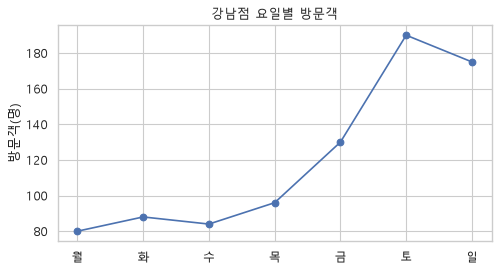

정렬: ['아메리카노', '라떼', '콜드브루', '샌드위치', '마카롱']


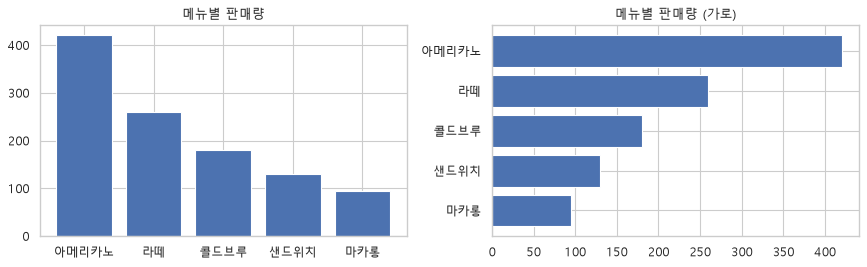

맨 위 막대: 아메리카노


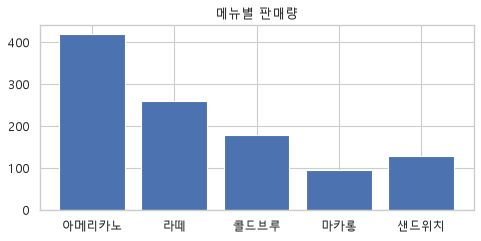

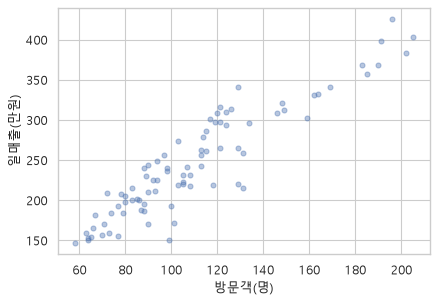

상관계수 0.920 → (나) 방문객이 많은 날은 매출도 높은 경향


In [28]:
# ---------- 2-1 ----------
# 문제 7: 질문 → 그래프 (변수 개수 · 유형)
# 왜 · 질문을 변수 개수 · 유형으로 바꿔 그래프를 고르는 규칙을 익히기 위해
pairs = {"(1) 12개월 회원 수 변화": "꺾은선 (시간 + 수치)",   # 시간 흐름
         "(2) 지점 5곳 매출 비교": "막대 (범주 + 값)",        # 항목 비교
         "(3) 광고비와 매출의 관계": "산점도 (수치 + 수치)",  # 관계
         "(4) 손님 나이 분포": "히스토그램 (수치 1개)"}       # 분포
for q, a in pairs.items():                                    # 질문마다
    print(q, "→", a)                                          # 답


# 문제 8: 요일별 방문객 꺾은선 · 동그라미 마커 · 단위가 든 세로축 이름
# 왜 · 마커와 단위가 든 축 이름으로 읽기 쉬운 꺾은선을 만들기 위해
fig, ax = plt.subplots(figsize=(7, 3.5))           # 칸 1개
ax.plot(week["요일"], week["방문객"], marker="o")  # 점마다 동그라미
ax.set_title("강남점 요일별 방문객")               # 제목
ax.set_ylabel("방문객(명)")                        # 단위 포함
plt.show()                                         # 화면에 띄움


# ---------- 2-2 ----------
# 문제 9: 판매량이 큰 순서로 세로 막대 · 세로축 0부터
# 왜 · 정렬하고 0부터 시작해야 막대 길이 비교가 정확해지기 때문에
m_sorted = menu.sort_values("판매량", ascending=False)  # 큰 순서
print("정렬:", m_sorted["메뉴"].tolist())               # 막대 순서
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))       # 문제 9 · 10을 나란히
axes[0].bar(m_sorted["메뉴"], m_sorted["판매량"])       # 세로 막대
axes[0].set_ylim(bottom=0)                              # 세로축 0에서 시작
axes[0].set_title("메뉴별 판매량")                      # 제목


# 문제 10: 가로 막대 · 1등이 맨 위 (barh는 첫 행을 아래에 그림 → 축 뒤집기)
# 왜 · 항목 이름이 길 때 가로 막대로 읽기 쉽게, 1등이 위에 오게 하기 위해
axes[1].barh(m_sorted["메뉴"], m_sorted["판매량"])             # 가로 막대
axes[1].invert_yaxis()                                         # 첫 행(1등)을 맨 위로
axes[1].set_title("메뉴별 판매량 (가로)")                      # 제목
plt.tight_layout()                                             # 간격 정리
plt.show()                                                     # 화면에 띄움
print("맨 위 막대:", axes[1].get_yticklabels()[0].get_text())  # 1등 확인


# 문제 15: 메뉴(범주)를 꺾은선으로 이으면 '메뉴 사이에 흐름'이 있는 것처럼 보임 → 막대로
# 왜 · 순서 없는 범주를 선으로 이으면 생기는 오해를 보이기 위해
fig, ax = plt.subplots(figsize=(7, 3))  # 칸 1개
ax.bar(menu["메뉴"], menu["판매량"])    # 고침: 범주 비교는 막대
ax.set_title("메뉴별 판매량")           # 제목
plt.show()                              # 화면에 띄움


# ---------- 2-3 ----------
# 문제 11: 방문객 vs 일매출 산점도 · 84개 점이 겹치므로 투명도 · 크기 조정
# 왜 · 점이 겹쳐 밀도가 안 보이는 문제를 투명도 · 크기로 해결하기 위해
fig, ax = plt.subplots(figsize=(6, 4))                         # 칸 1개
ax.scatter(sales["방문객"], sales["일매출"], alpha=0.4, s=20)  # 반투명 · 작은 점
ax.set_xlabel("방문객(명)")                                    # 가로 = 방문객
ax.set_ylabel("일매출(만원)")                                  # 세로 = 일매출
plt.show()                                                     # 화면에 띄움


# 문제 12: 산점도가 말해 주는 것 = 경향(상관) · 원인은 아님
# 왜 · 상관계수는 경향을 말할 뿐 원인은 아니라는 것을 확인하기 위해
r = sales["방문객"].corr(sales["일매출"])                              # 상관계수
print(f"상관계수 {r:.3f} → (나) 방문객이 많은 날은 매출도 높은 경향")  # 정답 (나)

**실행 흐름**

1. 2-4 bins에 따른 히스토그램
2. 막대 vs 히스토그램 비교

bins= 5 | 가장 큰 막대 27일 | 빈 구간 0개
bins=20 | 가장 큰 막대 9일 | 빈 구간 2개
bins=60 | 가장 큰 막대 5일 | 빈 구간 17개


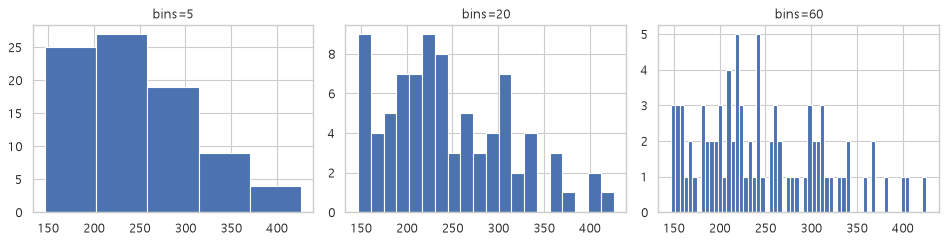

막대 | 가로: 범주(메뉴) | 세로: 값(판매량)
히스토그램 | 가로: 수치 구간(일매출) | 세로: 그 구간의 개수(일수)


In [29]:
# ---------- 2-4 ----------
# 문제 13: 일매출 히스토그램을 가로 3칸에 · bins 5 · 20 · 60
# 왜 · bins에 따라 같은 분포가 다르게 보인다는 것을 나란히 비교하기 위해
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))  # 가로 3칸
for ax, b in zip(axes, [5, 20, 60]):               # bins만 바꿈
    n, _, _ = ax.hist(sales["일매출"], bins=b)     # n = 구간별 개수
    ax.set_title(f"bins={b}")                      # 칸 제목에 bins
    print(f"bins={b:>2} | 가장 큰 막대 {int(n.max())}일 | 빈 구간 {(n == 0).sum()}개")  # 줌 비교
plt.tight_layout()                                 # 간격 정리
plt.show()                                         # 화면에 띄움


# 문제 14: 막대그래프 vs 히스토그램 (가로축 · 세로축 기준)
# 왜 · 가로축이 범주인지 구간인지로 두 그래프를 구분하기 위해
print("막대 | 가로: 범주(메뉴) | 세로: 값(판매량)")                         # 항목마다 막대
print("히스토그램 | 가로: 수치 구간(일매출) | 세로: 그 구간의 개수(일수)")  # 구간마다 막대

**실행 흐름**

1. 3-1 가로 2칸
2. 3-2 2 × 2 대시보드 · `sharey`
3. 3-3 axes 배열 · 단위 기준

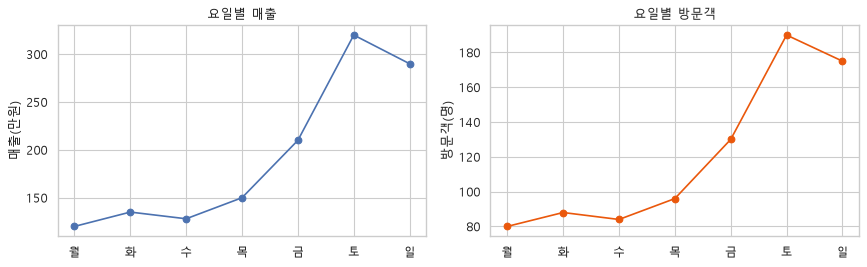

axes 모양: (2, 2)


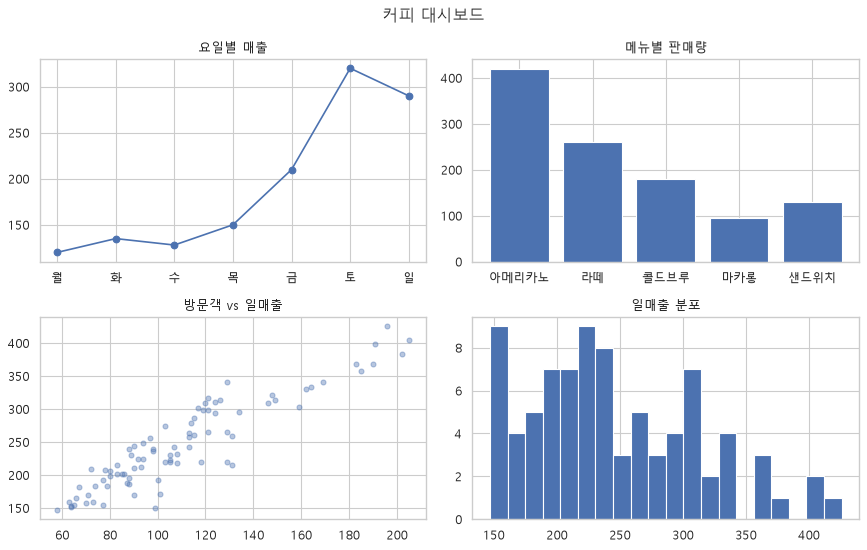

세 칸의 세로축 범위: [(0.0, 7.3), (0.0, 7.3), (0.0, 7.3)]


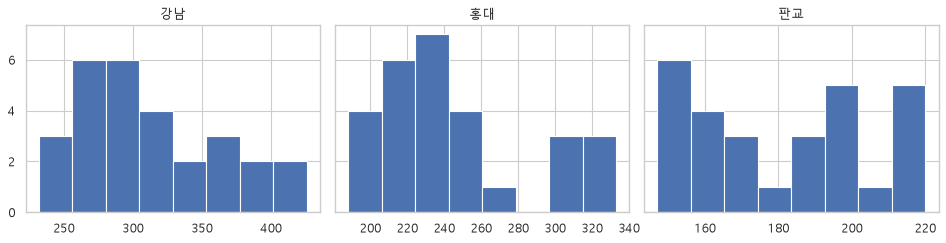

axes 정체: ndarray (2,)
에러: 'numpy.ndarray' object has no attribute 'set_title'


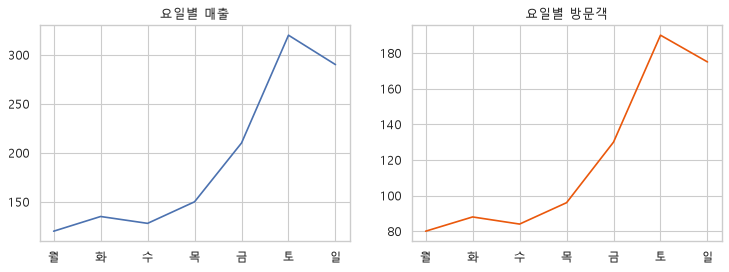

(1) 강남 vs 홍대 매출 | 단위 만원 · 만원 → 겹쳐 그리기
(2) 일매출 vs 방문객 | 단위 만원 · 명 → 칸 나누기


In [30]:
# ---------- 3-1 ----------
# 문제 16: 가로 2칸 · 칸마다 제목과 단위 · 겹치지 않게
# 왜 · 칸마다 제목 · 단위를 달고 겹치지 않게 배치하는 법을 익히기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                        # 1행 2열
axes[0].plot(week["요일"], week["매출"], marker="o")                     # 왼쪽 = 매출
axes[0].set(title="요일별 매출", ylabel="매출(만원)")                    # 제목 · 단위
axes[1].plot(week["요일"], week["방문객"], marker="o", color="#ea580c")  # 오른쪽 = 방문객
axes[1].set(title="요일별 방문객", ylabel="방문객(명)")                  # 제목 · 단위
plt.tight_layout()                                                       # 겹침 정리
plt.show()                                                               # 화면에 띄움


# 문제 17: 2행 2열 대시보드 · 전체 제목
# 왜 · 2차원 axes 배열에서 칸을 골라 그리는 법을 익히기 위해
fig, axes = plt.subplots(2, 2, figsize=(11, 7))                        # axes는 2 × 2 배열
axes[0, 0].plot(week["요일"], week["매출"], marker="o")                # 왼쪽 위 · 꺾은선
axes[0, 0].set_title("요일별 매출")                                    # 제목
axes[0, 1].bar(menu["메뉴"], menu["판매량"])                           # 오른쪽 위 · 막대
axes[0, 1].set_title("메뉴별 판매량")                                  # 제목
axes[1, 0].scatter(sales["방문객"], sales["일매출"], alpha=0.4, s=20)  # 왼쪽 아래 · 산점도
axes[1, 0].set_title("방문객 vs 일매출")                               # 제목
axes[1, 1].hist(sales["일매출"], bins=20)                              # 오른쪽 아래 · 히스토그램
axes[1, 1].set_title("일매출 분포")                                    # 제목
fig.suptitle("커피 대시보드")                                          # 전체 제목
plt.tight_layout()                                                     # 간격 정리
print("axes 모양:", axes.shape)                                        # [행, 열]로 칸 고르기
plt.show()                                                             # 화면에 띄움


# ---------- 3-2 ----------
# 문제 18: 지점 3곳 일매출 히스토그램 · 세로축 눈금을 같게 (sharey)
# 왜 · sharey로 눈금을 같게 해야 지점끼리 공정하게 비교되기 때문에
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)   # 세 칸이 세로축 공유
for ax, name in zip(axes, ["강남", "홍대", "판교"]):             # 지점마다
    ax.hist(sales.loc[sales["지점"] == name, "일매출"], bins=8)  # 그 지점의 28일
    ax.set_title(name)                                           # 칸 제목
plt.tight_layout()                                               # 간격 정리
# 같음
print("세 칸의 세로축 범위:", [tuple(round(float(v), 1) for v in ax.get_ylim()) for ax in axes])
plt.show()                                                       # 화면에 띄움


# ---------- 3-3 ----------
# 문제 19: plt.subplots(1, 2)의 axes는 칸 2개짜리 배열 → 칸을 골라서 그려야 함
# 왜 · axes 배열에 바로 그리려다 나는 에러를 미리 보기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))     # 칸 2개
print("axes 정체:", type(axes).__name__, axes.shape)  # ndarray (2,)
try:                                                  # 원본 그대로
    axes.set_title("요일별 매출")                     # 배열에는 set_title이 없음
except AttributeError as e:                           # 에러 메시지 읽기
    print("에러:", e)                                 # 'numpy.ndarray' object has no attribute ...
axes[0].plot(week["요일"], week["매출"])              # 고침: axes[0] = 첫 칸
axes[0].set_title("요일별 매출")                      # 칸에 제목
axes[1].plot(week["요일"], week["방문객"], color="#ea580c")  # 둘째 칸 = axes[1]
axes[1].set_title("요일별 방문객")                    # 칸에 제목
plt.show()                                            # 화면에 띄움


# 문제 20: 단위가 같으면 한 칸에 겹치고, 다르면 칸을 나눔
# 왜 · 단위에 따라 한 칸에 겹칠지 나눌지 정하는 기준을 세우기 위해
for case, unit, how in [("(1) 강남 vs 홍대 매출", "만원 · 만원", "겹쳐 그리기"),  # 같은 축 비교
                        ("(2) 일매출 vs 방문객", "만원 · 명", "칸 나누기")]:      # 단위가 다름
    print(f"{case} | 단위 {unit} → {how}")                                        # 판단

**실행 흐름**

1. 4-1 선 모양 옵션
2. 4-2 축 · 격자 · 강조 색
3. 4-3 화살표 주석 · 파일 저장

#e8590c -- 2.0 s
세로축: (0.0, 500.0)


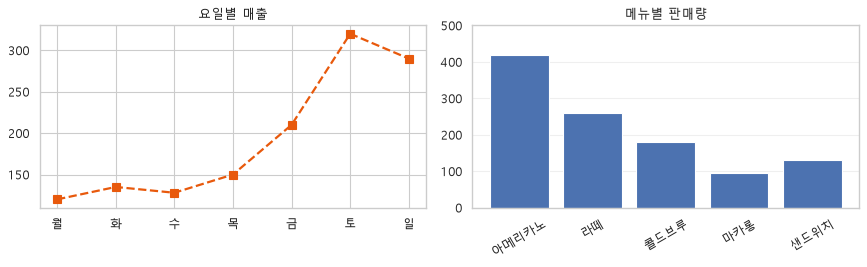

주황 막대: ['금']


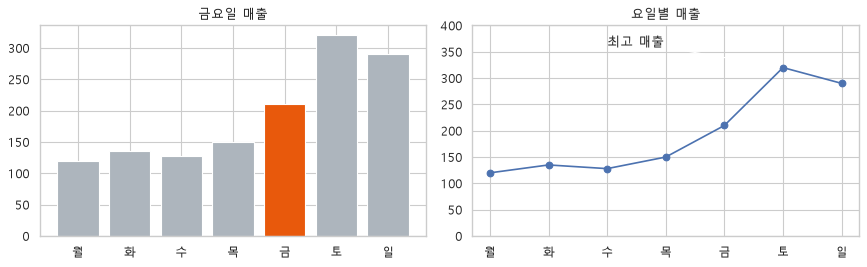

저장 완료 금요일매출.png True


In [31]:
# ---------- 4-1 ----------
# 문제 21: 색 · 점선 · 굵기 2 · 네모 마커 크기 8
# 왜 · 선 모양 옵션으로 강조할 선을 구분하기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                          # 문제 21 · 22 나란히
axes[0].plot(week["요일"], week["매출"], color="#e8590c", linestyle="--",  # 색 · 점선
             linewidth=2, marker="s", markersize=8)                        # 굵기 · 네모 · 크기
axes[0].set_title("요일별 매출")                                           # 제목


# 문제 22: 세로축 0 ~ 500 · 가로 글자 30도 · 가로 격자만 연하게 · 격자는 막대 뒤
# 왜 · 축 범위 · 글자 각도 · 격자를 정리해 읽기 쉬운 그래프를 만들기 위해
axes[1].bar(menu["메뉴"], menu["판매량"])                      # 막대
axes[1].set_ylim(0, 500)                                       # 세로축 고정
axes[1].tick_params(axis="x", rotation=30)                     # 가로 글자 기울이기
axes[1].grid(False)                                            # 스타일 기본 격자 끄기
axes[1].grid(axis="y", alpha=0.3)                              # 가로 방향 격자만 연하게
axes[1].set_axisbelow(True)                                    # 격자를 막대 뒤로
axes[1].set_title("메뉴별 판매량")                             # 제목
plt.tight_layout()                                             # 간격 정리
line = axes[0].get_lines()[0]                                  # 문제 21의 선
print(line.get_color(), line.get_linestyle(), line.get_linewidth(), line.get_marker())  # 확인
print("세로축:", tuple(float(v) for v in axes[1].get_ylim()))  # (0.0, 500.0)
plt.show()                                                     # 화면에 띄움


# ---------- 4-2 ----------
# 문제 23: 금요일 하나만 주황 · 나머지 회색 (색 목록을 한 번에)
# 왜 · 강조할 막대 하나만 색을 달리해 시선을 모으기 위해
colors = ["#e8590c" if d == "금" else "#adb5bd" for d in week["요일"]]  # 막대마다 색
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))                       # 문제 23 · 24 나란히
axes[0].bar(week["요일"], week["매출"], color=colors)                   # 한 번만 그림
axes[0].set_title("금요일 매출")                                        # 제목
print("주황 막대:", [d for d, c in zip(week["요일"], colors) if c == "#e8590c"])  # 강조된 요일


# 문제 24: 토요일(320)을 가리키는 화살표 + '최고 매출' (글자는 수요일 위 360 근처)
# 왜 · 말로 설명할 핵심을 그래프 안에 직접 표시하기 위해
axes[1].plot(week["요일"], week["매출"], marker="o")         # 꺾은선
axes[1].annotate("최고 매출", xy=(5, 320), xytext=(2, 360),  # 가리킬 곳 · 글자 위치 (0 = 월)
                 arrowprops=dict(arrowstyle="->"))           # 화살표 모양
axes[1].set_ylim(0, 400)                                     # 글자가 들어갈 자리
axes[1].set_title("요일별 매출")                             # 제목
plt.tight_layout()                                           # 간격 정리
plt.show()                                                   # 화면에 띄움


# ---------- 4-3 ----------
# 문제 25: 문제 23의 그림을 파일로 · 해상도 150 · 제목 잘림 없이
# 왜 · 보고서에 쓸 수 있게 해상도를 정하고 제목이 잘리지 않게 저장하기 위해
fig, ax = plt.subplots(figsize=(7, 3.5))                # 칸 1개
ax.bar(week["요일"], week["매출"], color=colors)        # 금요일 강조 막대
ax.set_title("금요일 매출")                             # 제목
path = SAVE / "금요일매출.png"                          # 노트북 옆 실습파일 폴더
fig.savefig(path, dpi=150, bbox_inches="tight")         # bbox_inches="tight" = 잘림 방지
plt.close(fig)                                          # 저장만 하고 화면에는 안 띄움
print("저장 완료", path.name, path.stat().st_size > 0)  # 파일이 생겼는지

**실행 흐름**

1. 토요일 매출 · 평일 평균 · 지점 평균 · 1등 메뉴 비중 계산
2. 계산한 숫자로 '발견한 사실' 제목 문장 출력

In [32]:
# 문제 26: 제목은 '무엇을 그렸나'가 아니라 '무엇을 발견했나' (숫자는 계산해서)
# 왜 · 제목만 읽어도 결론이 전달되게 하기 위해
sat = week.loc[week["요일"] == "토", "매출"].item()                                # 토요일 매출
weekday_mean = week.loc[week["요일"].isin(list("월화수목")), "매출"].mean()        # 월 ~ 목 평균
shop_mean = sales.groupby("지점")["일매출"].mean().round(1)                        # 지점별 평균
top_share = menu["판매량"].max() / menu["판매량"].sum()                            # 1등 메뉴 비중
# 고친 제목 1
print(f"요일별 매출 → 토요일 매출({sat})이 월 ~ 목 평균의 {sat / weekday_mean:.1f}배")
ratio = shop_mean["강남"] / shop_mean["판교"]                                      # 1등 ÷ 꼴찌
print(f"지점별 일매출 → 강남 평균 {shop_mean['강남']}만원, 판교의 {ratio:.1f}배")  # 고친 제목 2
print(f"메뉴별 판매량 → 아메리카노가 전체 판매의 {top_share:.0%}")                 # 고친 제목 3

요일별 매출 → 토요일 매출(320)이 월 ~ 목 평균의 2.4배
지점별 일매출 → 강남 평균 311.3만원, 판교의 1.7배
메뉴별 판매량 → 아메리카노가 전체 판매의 39%


**실행 흐름**

1. 5-1 seaborn 한 줄 · estimator
2. 5-2 countplot · histplot
3. 5-3 hue · style 산점도

막대 높이: [311.32, 246.57, 181.5]
groupby 평균: [311.32, 246.57, 181.5]


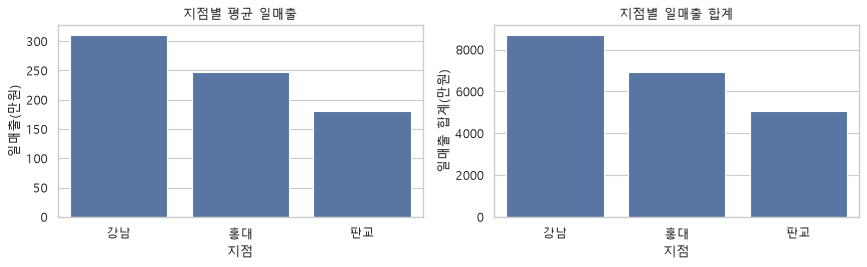

합계: [8717.0, 6904.0, 5082.0]
요일별 개수: [12, 12, 12, 12, 12, 12, 12]


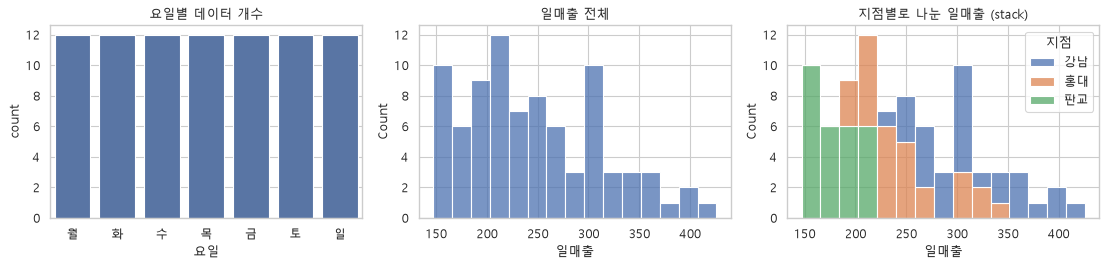

구분 표시 개수: 3


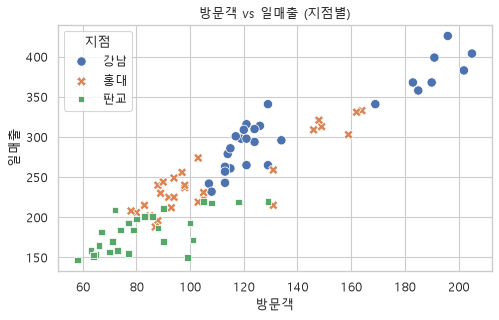

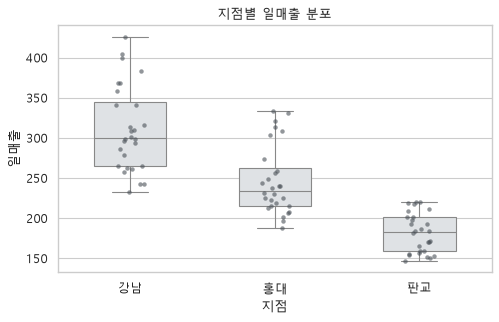

In [33]:
# ---------- 5-1 ----------
# 문제 27: matplotlib 3줄 = seaborn 한 줄 (지점별 평균 일매출)
# 왜 · 같은 그림을 더 짧게 그리는 seaborn의 장점을 비교하기 위해
평균 = sales.groupby("지점", sort=False)["일매출"].mean()       # 원본 계산 · 처음 나온 지점 순서
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))               # 문제 27 · 28 비교
sns.barplot(data=sales, x="지점", y="일매출", errorbar=None, ax=axes[0])  # 평균을 알아서 계산
axes[0].set(title="지점별 평균 일매출", ylabel="일매출(만원)")  # 제목 · 세로축 이름
print("막대 높이:", [round(float(p.get_height()), 2) for p in axes[0].patches])  # seaborn이 그린 값
print("groupby 평균:", 평균.round(2).tolist())                  # 같은 값 · 같은 순서


# 문제 28: barplot의 기본 estimator = 평균 → 합계로 바꾸면 28배
# 왜 · 기본값이 평균이라 합계가 필요하면 바꿔야 한다는 함정을 보이기 위해
sns.barplot(data=sales, x="지점", y="일매출", estimator="sum", errorbar=None, ax=axes[1])  # 합계
axes[1].set(title="지점별 일매출 합계", ylabel="일매출 합계(만원)")         # 제목
plt.tight_layout()                                                          # 간격 정리
plt.show()                                                                  # 화면에 띄움
print("합계:", sales.groupby("지점", sort=False)["일매출"].sum().tolist())  # 평균 × 28일


# ---------- 5-2 ----------
# 문제 29: 요일별 데이터 개수 · 월 ~ 일 순서 (order)
# 왜 · 범주 순서를 order로 고정해 요일이 뒤섞이지 않게 하기 위해
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))                           # 문제 29 · 30
sns.countplot(data=sales, x="요일", order=순서, ax=axes[0])                 # 행 개수를 셈
axes[0].set_title("요일별 데이터 개수")                                     # 제목
print("요일별 개수:", sales["요일"].value_counts().reindex(순서).tolist())  # 모두 12


# 문제 30: 왼쪽 = 전체 히스토그램 · 오른쪽 = 지점별 색 · 쌓기
# 왜 · 전체 분포와 지점별 분포를 한 번에 비교하기 위해
sns.histplot(data=sales, x="일매출", bins=15, ax=axes[1])  # 전체 84일
axes[1].set_title("일매출 전체")                           # 제목
sns.histplot(data=sales, x="일매출", hue="지점", multiple="stack", bins=15, ax=axes[2])  # 지점별 색
axes[2].set_title("지점별로 나눈 일매출 (stack)")          # 제목
plt.tight_layout()                                         # 간격 정리
plt.show()                                                 # 화면에 띄움


# 문제 31: 산점도에 지점을 색(hue)과 모양(style) 둘 다로 · 점 크기 70
# 왜 · 색을 구분하기 어려운 사람도 모양으로 구분할 수 있게 하기 위해
fig, ax = plt.subplots(figsize=(7, 4))                      # 칸 1개
# 2중 구분
sns.scatterplot(data=sales, x="방문객", y="일매출", hue="지점", style="지점", s=70, ax=ax)
ax.set_title("방문객 vs 일매출 (지점별)")                   # 제목
print("구분 표시 개수:", len(ax.get_legend().get_texts()))  # 범례 항목 = 지점 3개
plt.show()                                                  # 화면에 띄움


# ---------- 5-3 ----------
# 문제 32: 지점별 일매출 박스플롯 + 실제 점 (stripplot)
# 왜 · 요약 상자 뒤에 숨은 실제 데이터 개수 · 위치도 함께 보기 위해
fig, ax = plt.subplots(figsize=(7, 4))                                    # 칸 1개
sns.boxplot(data=sales, x="지점", y="일매출", color="#dee2e6", width=0.5, ax=ax)  # 연한 상자
sns.stripplot(data=sales, x="지점", y="일매출", color="#495057", size=4,  # 진한 점
              alpha=0.6, jitter=True, ax=ax)                              # 반투명 · 좌우로 흩뿌림
ax.set_title("지점별 일매출 분포")                                        # 제목
plt.show()                                                                # 화면에 띄움

**실행 흐름**

1. 5-4 박스플롯 숫자 확인
2. 5-5 피벗 → 히트맵 · 기준선 · catplot

강남 | Q1 265.0 | 중앙값 299.5 | Q3 345.2
수염 232 ~ 426
수염 밖 점: []
요일      월      화      수      목      금      토      일
지점                                                 
강남  284.0  265.0  288.0  290.0  290.0  377.0  385.0
판교  173.0  166.0  184.0  180.0  176.0  195.0  196.0
홍대  236.0  226.0  214.0  216.0  238.0  280.0  316.0


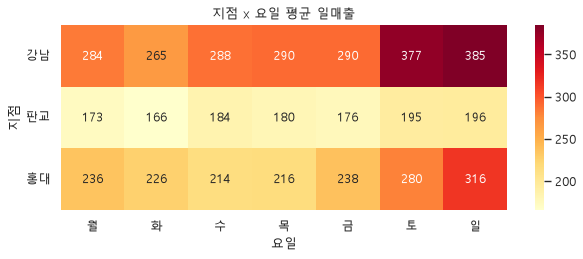

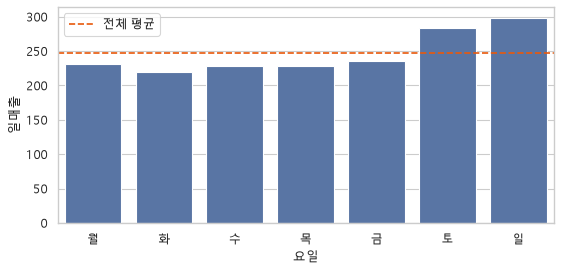

전체 평균 246.5만원
경고: catplot is a figure-level function and does not acce
ax의 막대: 0 | 새 그림판이 따로 생김: True


방법 1 · ax의 막대: 7


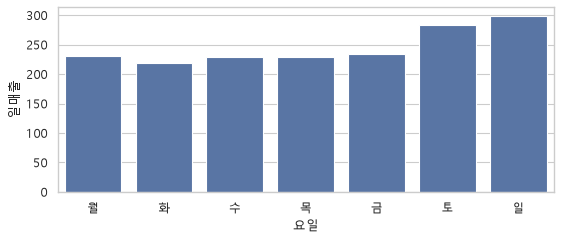

방법 2 결과: FacetGrid


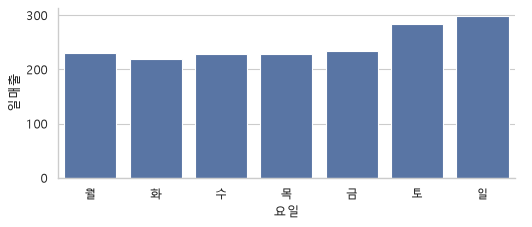

In [34]:
# 문제 33: 박스플롯 다섯 부분을 숫자로 확인 (강남점)
# 왜 · 그림에서 읽은 값이 실제 숫자와 맞는지 검증하기 위해
g = sales.loc[sales["지점"] == "강남", "일매출"]               # 강남 28일
q1, med, q3 = g.quantile([0.25, 0.5, 0.75])                    # 상자 아래 · 가운데 선 · 위
iqr = q3 - q1                                                  # 상자 길이
inside = g[(g >= q1 - 1.5 * iqr) & (g <= q3 + 1.5 * iqr)]      # 수염이 닿는 범위
print(f"강남 | Q1 {q1:.1f} | 중앙값 {med:.1f} | Q3 {q3:.1f}")  # 상자 아래 · 가운데 선 · 위
print(f"수염 {inside.min():.0f} ~ {inside.max():.0f}")         # fence 안의 끝값
print("수염 밖 점:", g[~g.isin(inside)].tolist())              # 이상점 후보


# ---------- 5-4 ----------
# 문제 34: 행 = 지점 · 열 = 요일 · 값 = 일매출 평균 → 먼저 print로 확인
# 왜 · 히트맵을 그리기 전에 표를 print로 먼저 확인하기 위해
pv = sales.pivot_table(index="지점", columns="요일", values="일매출", aggfunc="mean")  # 재구성
pv = pv[순서]       # 열을 월 ~ 일 순서로
print(pv.round(0))  # 히트맵 전에 눈으로 확인


fig, ax = plt.subplots(figsize=(9, 3))                        # 가로로 긴 칸
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax)  # 칸 안 숫자 · 소수점 없이
ax.tick_params(axis="y", rotation=0)                          # 누운 세로축 글자 세우기
ax.set_title("지점 x 요일 평균 일매출")                       # 제목
plt.show()                                                    # 화면에 띄움


# ---------- 5-5 ----------
# 문제 35: seaborn으로 그리고 matplotlib으로 기준선 추가
# 왜 · seaborn 그림에도 ax를 받아 matplotlib 기능을 더할 수 있음을 보이기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))  # ax를 직접 만들어 seaborn에 넘김
sns.barplot(data=sales, x="요일", y="일매출", order=순서, errorbar=None, ax=ax)  # 요일별 평균
total = sales["일매출"].mean()                                                   # 전체 평균
ax.axhline(total, color="#e8590c", linestyle="--", label="전체 평균")            # 주황 점선 기준선
ax.legend()                                                                      # 범례
plt.show()                                                                       # 화면에 띄움
print(f"전체 평균 {total:.1f}만원")                                              # 기준선 높이


# 문제 36: catplot은 그림판(fig)을 스스로 만드는 '그림 단위' 함수 → ax를 쓰지 않음
# 왜 · 그림 단위 함수에 ax를 넘길 때 생기는 문제와 해결법을 확인하기 위해
fig, ax = plt.subplots(figsize=(8, 3.5))              # 원본처럼 칸을 먼저 만듦
with warnings.catch_warnings(record=True) as caught:  # 원본 그대로 실행 · 경고 모으기
    warnings.simplefilter("always")                   # 경고를 빠짐없이 기록
    g0 = sns.catplot(data=sales, x="요일", y="일매출", kind="bar", order=순서,  # 원본 코드
                     errorbar=None, ax=ax)            # ax를 넘김
msg = [str(w.message) for w in caught if "figure-level" in str(w.message)][0]  # catplot 경고
print("경고:", msg[:52])                              # seaborn 0.13은 에러 대신 경고
print("ax의 막대:", len(ax.patches), "| 새 그림판이 따로 생김:", g0.figure is not fig)  # ax 무시
plt.close("all")                                      # 잘못 만든 그림 두 개 정리


# 방법 1: 칸 단위 함수(barplot)로 바꾸면 ax에 그림
# 왜 · 기존 칸 배치 안에 그리려면 칸 단위 함수를 써야 하기 때문에
fig, ax = plt.subplots(figsize=(8, 3))                                           # 칸 1개
sns.barplot(data=sales, x="요일", y="일매출", order=순서, errorbar=None, ax=ax)  # ax에 그림
print("방법 1 · ax의 막대:", len(ax.patches))                                    # 7개
plt.show()                                                                       # 화면에 띄움


# 방법 2: catplot을 그대로 쓰되 ax를 빼고 크기는 height · aspect로
# 왜 · 그림 단위 함수는 크기를 height · aspect로 정해야 하기 때문에
g = sns.catplot(data=sales, x="요일", y="일매출", kind="bar", order=순서,  # ax 없음
                errorbar=None, height=3, aspect=2.2)  # 세로 3인치 · 가로 = 세로 × 2.2
print("방법 2 결과:", type(g).__name__)               # FacetGrid (그림판 단위)
plt.show()                                            # 화면에 띄움

**실행 흐름**

1. 6-1 잘린 축 비교
2. 6-2 이중축 · 파이 vs 막대

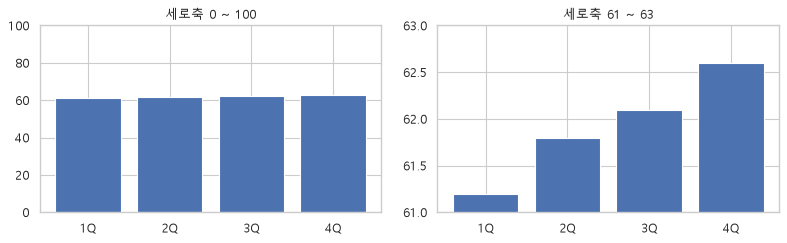

실제 차이: 1.4%p
실제 비율 1.10배 | 세로축 시작 4.0점이면 높이가 3배로 보임


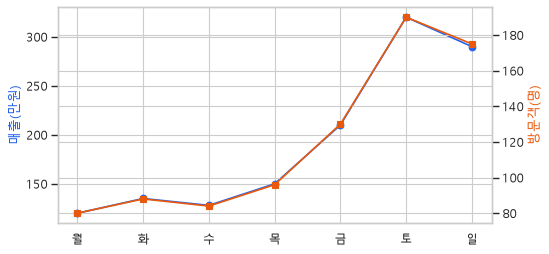

왼쪽 축: (110, 330) | 오른쪽 축: (74, 196)


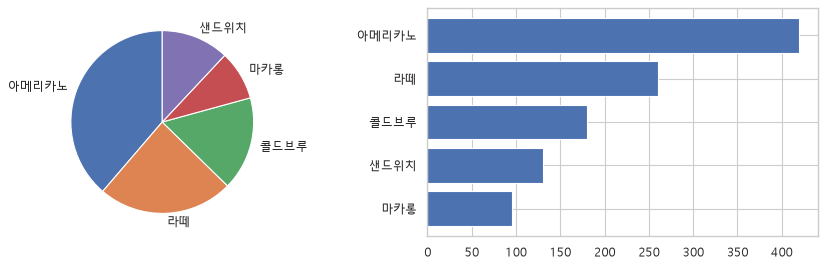

콜드브루 180 vs 샌드위치 130


In [35]:
# ---------- 6-1 ----------
# 문제 37: 같은 데이터, 세로축 0 ~ 100 vs 61 ~ 63
# 왜 · 축 범위만으로 차이가 과장되는 그래프를 직접 확인하기 위해
q = pd.DataFrame({"분기": ["1Q", "2Q", "3Q", "4Q"],       # 원본 데이터
                  "재구매율": [61.2, 61.8, 62.1, 62.6]})  # %
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))         # 가로 2칸
for ax, lim in zip(axes, [(0, 100), (61, 63)]):           # 축 범위만 다름
    ax.bar(q["분기"], q["재구매율"])                      # 같은 막대
    ax.set_ylim(*lim)                                     # 세로축
    ax.set_title(f"세로축 {lim[0]} ~ {lim[1]}")           # 칸 제목
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 화면에 띄움
diff = q["재구매율"].iloc[-1] - q["재구매율"].iloc[0]     # 4Q - 1Q
print(f"실제 차이: {diff:.1f}%p")                         # 1.4 퍼센트포인트


# 문제 40: 4.6점 막대가 4.2점의 세 배로 보이려면 축이 어디서 시작했나
# 왜 · 잘린 축이 만드는 착시를 숫자로 계산해 보기 위해
a, b = 4.6, 4.2               # 우리 회사 · B사
base = (a - 3 * b) / (1 - 3)  # (a - x) = 3 × (b - x)를 x에 대해 풂
print(f"실제 비율 {a / b:.2f}배 | 세로축 시작 {base:.1f}점이면 높이가 3배로 보임")  # 축부터 확인


# ---------- 6-2 ----------
# 문제 38: 이중축 (매출 만원 + 방문객 명)
# 왜 · 단위가 다른 두 값을 한 그림에 그릴 때의 방법과 주의점을 보기 위해
fig, ax1 = plt.subplots(figsize=(7, 3.5))                                   # 왼쪽 축
ax1.plot(week["요일"], week["매출"], color="#2563eb", marker="o")           # 매출
ax1.set_ylabel("매출(만원)", color="#2563eb")                               # 왼쪽 축 이름
ax2 = ax1.twinx()  # 같은 가로축 · 오른쪽에 새 세로축
ax2.plot(week["요일"], week["방문객"], color="#e8590c", marker="s")         # 방문객
ax2.set_ylabel("방문객(명)", color="#e8590c")                               # 오른쪽 축 이름
plt.show()                                                                  # 화면에 띄움
print("왼쪽 축:", tuple(round(v) for v in ax1.get_ylim()), "| 오른쪽 축:",  # 축마다 범위가 다름
      tuple(round(v) for v in ax2.get_ylim()))  # 범위를 바꾸면 두 선의 겹침이 달라짐
# 문제점 1: 두 축의 범위를 마음대로 정할 수 있어 '같이 움직인다'는 인상을 만들 수 있음
# 문제점 2: 어느 선이 어느 축인지 헷갈림 → 칸을 나누는 것이 기본 (문제 20)


# 문제 39: 파이 vs 정렬한 가로 막대 — 콜드브루와 샌드위치 중 어느 쪽이 더 많은가
# 왜 · 비슷한 크기의 항목은 파이보다 정렬한 막대에서 비교가 쉽다는 것을 보이기 위해
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # 가로 2칸
axes[0].pie(menu["판매량"], labels=menu["메뉴"], startangle=90)  # 조각 크기로 비교
m_asc = menu.sort_values("판매량")                 # barh는 아래부터 → 오름차순이면 1등이 맨 위
axes[1].barh(m_asc["메뉴"], m_asc["판매량"])       # 길이로 비교
plt.tight_layout()                                 # 간격 정리
plt.show()                                         # 화면에 띄움
cb, sw = menu.set_index("메뉴").loc[["콜드브루", "샌드위치"], "판매량"]  # 두 메뉴
print(f"콜드브루 {cb} vs 샌드위치 {sw}")           # 막대 길이로는 바로 · 파이 조각으로는 어려움

**실행 흐름**

1. 객단가로 주말 효과 나눠 보기
2. 지점별 주말 효과 비교
3. 보고용 한 장 만들기

평일 객단가 2.41만원 | 주말 객단가 1.95만원 | 주말이 19% 낮음


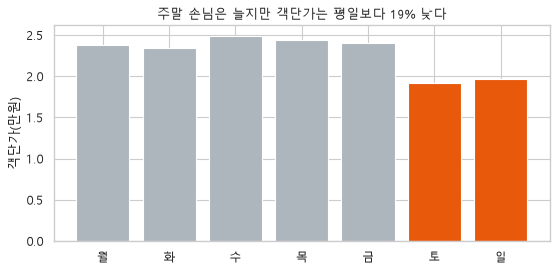

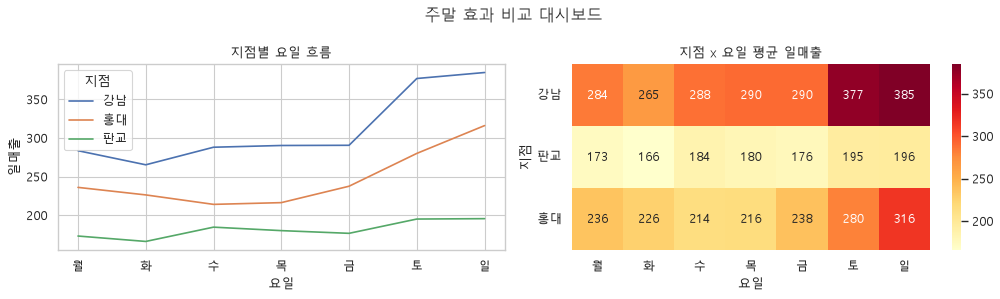

주말 매출 ÷ 평일 매출: {'강남': 1.34, '판교': 1.11, '홍대': 1.32}


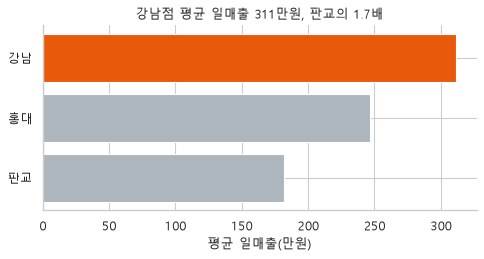

1등: 강남 | 저장: True


In [36]:
# ---------- 7. 종합 실습 ----------
# 문제 41: 주말에는 손님이 늘어난 만큼 매출도 늘어나는가? → 객단가 = 일매출 ÷ 방문객
# 왜 · 매출 증가가 손님 수 때문인지 객단가 때문인지 나눠 보기 위해
sales["객단가"] = sales["일매출"] / sales["방문객"]            # 손님 1명당 매출(만원)
by_day = sales.groupby("요일")["객단가"].mean().reindex(순서)  # 요일별 평균 객단가
is_weekend = sales["요일"].isin(["토", "일"])                  # 주말 표시
wd, we = sales.loc[~is_weekend, "객단가"].mean(), sales.loc[is_weekend, "객단가"].mean()  # 평균
print(f"평일 객단가 {wd:.2f}만원 | 주말 객단가 {we:.2f}만원 | 주말이 {1 - we / wd:.0%} 낮음")  # 답


fig, ax = plt.subplots(figsize=(8, 3.5))                                      # 칸 1개
colors = ["#e8590c" if d in ("토", "일") else "#adb5bd" for d in 순서]        # 주말 2칸 강조
ax.bar(순서, by_day.values, color=colors)                                     # 요일별 평균 객단가
ax.set_ylabel("객단가(만원)")                                                 # 단위
ax.set_title(f"주말 손님은 늘지만 객단가는 평일보다 {1 - we / wd:.0%} 낮다")  # 발견한 사실
plt.show()                                                                    # 화면에 띄움


# 문제 42: 주말 효과는 세 지점에서 똑같이 나타나는가?
# 왜 · 전체 평균에 가려진 지점별 차이를 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))                             # 가로 2칸
sns.lineplot(data=sales, x="요일", y="일매출", hue="지점", errorbar=None, ax=axes[0])  # 지점별 선
axes[0].set_title("지점별 요일 흐름")                                         # 칸 제목
pv2 = sales.pivot_table(index="지점", columns="요일", values="일매출")[순서]  # 지점 x 요일 평균
sns.heatmap(pv2, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1])            # 히트맵
axes[1].tick_params(axis="y", rotation=0)                                     # 세로 글자 세우기
axes[1].set_title("지점 x 요일 평균 일매출")                                  # 칸 제목
fig.suptitle("주말 효과 비교 대시보드")                                       # 전체 제목
plt.tight_layout()                                                            # 간격 정리
plt.show()                                                                    # 화면에 띄움
# 주말 ÷ 평일
lift = (pv2[["토", "일"]].mean(axis=1) / pv2[list("월화수목금")].mean(axis=1)).round(2)
print("주말 매출 ÷ 평일 매출:", lift.to_dict())                               # 지점마다 배율 비교


# 문제 43: 사장님께 드릴 한 장 · 1등만 강조 · 테두리 정리 · 발견한 사실 제목 · 저장
# 왜 · 결론 하나가 바로 보이도록 강조 · 정리 · 제목을 모두 적용하기 위해
avg = sales.groupby("지점")["일매출"].mean().sort_values()          # 오름차순 → barh 맨 위가 1등
best = avg.idxmax()                                                 # 1등 지점
fig, ax = plt.subplots(figsize=(7, 3))                              # 칸 1개
bar_colors = ["#e8590c" if k == best else "#adb5bd" for k in avg.index]  # 1등만 주황
ax.barh(avg.index, avg.values, color=bar_colors)                    # 가로 막대
ax.spines[["top", "right"]].set_visible(False)                      # 위 · 오른쪽 테두리 제거
ax.set_ylabel("")                                                   # 지점 이름이 이미 있으므로 비움
ax.set_xlabel("평균 일매출(만원)")                                  # 단위
# 사실
ax.set_title(f"{best}점 평균 일매출 {avg.max():.0f}만원, 판교의 {avg.max() / avg['판교']:.1f}배")
fig.savefig(SAVE / "지점별매출.png", dpi=150, bbox_inches="tight")  # 해상도 150 · 잘림 없이
plt.show()                                                          # 화면에도 띄움
print("1등:", best, "| 저장:", (SAVE / "지점별매출.png").exists())  # 결과 확인